In [3]:
from google.colab import drive
drive.mount('/content/drive')

import os

base = '/content/drive/MyDrive/FYP_Neckline'
subfolders = ['data/raw', 'data/annotated', 'data/splits',
              'results', 'checkpoints', 'figures', 'notebooks']

for sub in subfolders:
    path = os.path.join(base, sub)
    if not os.path.exists(path):
        os.makedirs(path)
        print(f"Created: {path}")
    else:
        print(f"Already exists: {path}")

print("\nDone. Folder tree ready at:", base)

Mounted at /content/drive
Already exists: /content/drive/MyDrive/FYP_Neckline/data/raw
Already exists: /content/drive/MyDrive/FYP_Neckline/data/annotated
Already exists: /content/drive/MyDrive/FYP_Neckline/data/splits
Already exists: /content/drive/MyDrive/FYP_Neckline/results
Already exists: /content/drive/MyDrive/FYP_Neckline/checkpoints
Already exists: /content/drive/MyDrive/FYP_Neckline/figures
Already exists: /content/drive/MyDrive/FYP_Neckline/notebooks

Done. Folder tree ready at: /content/drive/MyDrive/FYP_Neckline


In [ ]:
import json

test_path = '/content/drive/MyDrive/FYP_Neckline/results/test_write.json'
test_data = {"status": "ok", "note": "Drive write/read test"}

with open(test_path, 'w') as f:
    json.dump(test_data, f)
print("Written to:", test_path)

with open(test_path, 'r') as f:
    loaded = json.load(f)
print("Read back:", loaded)

Written to: /content/drive/MyDrive/FYP_Neckline/results/test_write.json
Read back: {'status': 'ok', 'note': 'Drive write/read test'}


In [ ]:
from datasets import load_dataset
import statistics, json, os

ds_train = load_dataset("detection-datasets/fashionpedia", split="train")
ds_val = load_dataset("detection-datasets/fashionpedia", split="val")

neckline_cat_id = 33
total = 0
with_neckline = 0
short_sides = []

for split_name, ds in [("train", ds_train), ("val", ds_val)]:
    for ex in ds:
        total += 1
        if neckline_cat_id in ex['objects']['category']:
            with_neckline += 1
        short_sides.append(min(ex['width'], ex['height']))

result = {
    "total_images": total,
    "images_with_neckline": with_neckline,
    "pct_with_neckline": round(100 * with_neckline / total, 2),
    "median_short_side_px": statistics.median(short_sides),
    "min_short_side_px": min(short_sides),
    "pct_below_400px_short_side": round(100 * sum(s < 400 for s in short_sides) / total, 2),
}

print(json.dumps(result, indent=2))

os.makedirs('/content/drive/MyDrive/FYP_Neckline/results', exist_ok=True)
with open('/content/drive/MyDrive/FYP_Neckline/results/fashionpedia_audit.json', 'w') as f:
    json.dump(result, f, indent=2)
print("Saved to results/fashionpedia_audit.json")

README.md:   0%|          | 0.00/5.22k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/1.78k [00:00<?, ?B/s]

data/train-00000-of-00007-fe108070118553(…): reconstructing file:   0%|          |  0.00B /  482MB            

data/train-00000-of-00007-fe108070118553(…): downloading bytes:           |  0.00B            

data/train-00001-of-00007-f41a5a9c38c900(…): reconstructing file:   0%|          |  0.00B /  480MB            

...

data/val-00000-of-00001-0b29e85429788213(…): reconstructing file:   0%|          |  0.00B / 84.8MB            

data/val-00000-of-00001-0b29e85429788213(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/45623 [00:00<?, ? examples/s]

Generating val split:   0%|          | 0/1158 [00:00<?, ? examples/s]

{
  "total_images": 46781,
  "images_with_neckline": 34055,
  "pct_with_neckline": 72.8,
  "median_short_side_px": 682,
  "min_short_side_px": 232,
  "pct_below_400px_short_side": 0.36
}
Saved to results/fashionpedia_audit.json


In [ ]:
import random, json, os

random.seed(42)  # fixed seed — same split every time this is re-run

neckline_cat_id = 33
manifest = []

for split_name, ds in [("train", ds_train), ("val", ds_val)]:
    for i, ex in enumerate(ds):
        cats = ex['objects']['category']
        if neckline_cat_id in cats:
            idx = cats.index(neckline_cat_id)
            manifest.append({
                "hf_split": split_name,
                "hf_index": i,
                "image_id": ex["image_id"],
                "width": ex["width"],
                "height": ex["height"],
                "neckline_bbox": ex["objects"]["bbox"][idx],
            })

print("Total neckline-annotated images:", len(manifest))

random.shuffle(manifest)
n = len(manifest)
train_end = int(n * 0.8)
val_end = int(n * 0.9)

splits = {
    "train": manifest[:train_end],
    "val": manifest[train_end:val_end],
    "test": manifest[val_end:],
}

for name, items in splits.items():
    print(f"{name}: {len(items)} images")

os.makedirs('/content/drive/MyDrive/FYP_Neckline/data/splits', exist_ok=True)
for name, items in splits.items():
    path = f'/content/drive/MyDrive/FYP_Neckline/data/splits/{name}_manifest.json'
    with open(path, 'w') as f:
        json.dump(items, f)
    print("Saved:", path)

Total neckline-annotated images: 34055
train: 27244 images
val: 3405 images
test: 3406 images
Saved: /content/drive/MyDrive/FYP_Neckline/data/splits/train_manifest.json
Saved: /content/drive/MyDrive/FYP_Neckline/data/splits/val_manifest.json
Saved: /content/drive/MyDrive/FYP_Neckline/data/splits/test_manifest.json


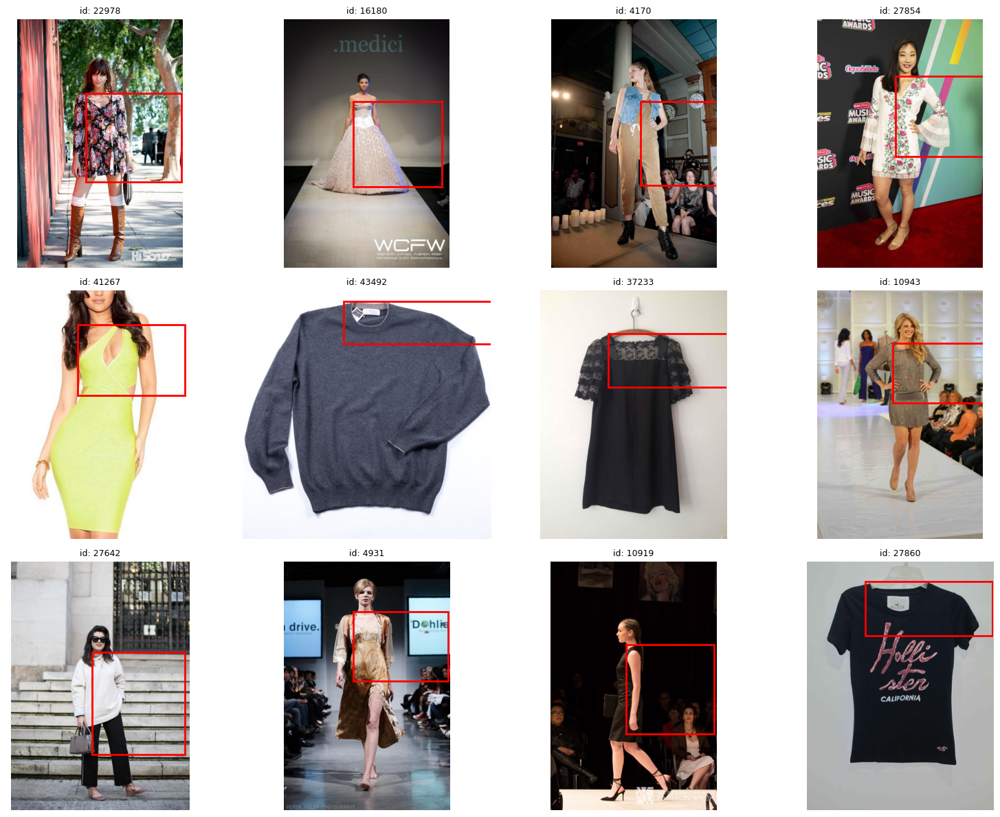

Saved: figures/phase2_sample_boxes.png


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import random

random.seed(7)
sample = random.sample(splits["train"], 12)

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

for ax, item in zip(axes, sample):
    ex = ds_train[item["hf_index"]] if item["hf_split"] == "train" else ds_val[item["hf_index"]]
    img = ex["image"]
    x, y, w, h = item["neckline_bbox"]

    ax.imshow(img)
    rect = patches.Rectangle((x, y), w, h, linewidth=2, edgecolor='red', facecolor='none')
    ax.add_patch(rect)
    ax.set_title(f"id: {item['image_id']}", fontsize=9)
    ax.axis('off')

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/FYP_Neckline/figures/phase2_sample_boxes.png', dpi=150)
plt.show()
print("Saved: figures/phase2_sample_boxes.png")

In [ ]:
import random, json, os

random.seed(42)

neckline_cat_id = 33
manifest = []

for split_name, ds in [("train", ds_train), ("val", ds_val)]:
    for i, ex in enumerate(ds):
        cats = ex['objects']['category']
        if neckline_cat_id in cats:
            idx = cats.index(neckline_cat_id)
            x_min, y_min, x_max, y_max = ex["objects"]["bbox"][idx]
            manifest.append({
                "hf_split": split_name,
                "hf_index": i,
                "image_id": ex["image_id"],
                "width": ex["width"],
                "height": ex["height"],
                "neckline_bbox_xywh": [x_min, y_min, x_max - x_min, y_max - y_min],  # corrected
            })

print("Total neckline-annotated images:", len(manifest))

random.shuffle(manifest)
n = len(manifest)
train_end = int(n * 0.8)
val_end = int(n * 0.9)

splits = {
    "train": manifest[:train_end],
    "val": manifest[train_end:val_end],
    "test": manifest[val_end:],
}

for name, items in splits.items():
    print(f"{name}: {len(items)} images")
    path = f'/content/drive/MyDrive/FYP_Neckline/data/splits/{name}_manifest.json'
    with open(path, 'w') as f:
        json.dump(items, f)
    print("Saved:", path)

Total neckline-annotated images: 34055
train: 27244 images
Saved: /content/drive/MyDrive/FYP_Neckline/data/splits/train_manifest.json
val: 3405 images
Saved: /content/drive/MyDrive/FYP_Neckline/data/splits/val_manifest.json
test: 3406 images
Saved: /content/drive/MyDrive/FYP_Neckline/data/splits/test_manifest.json


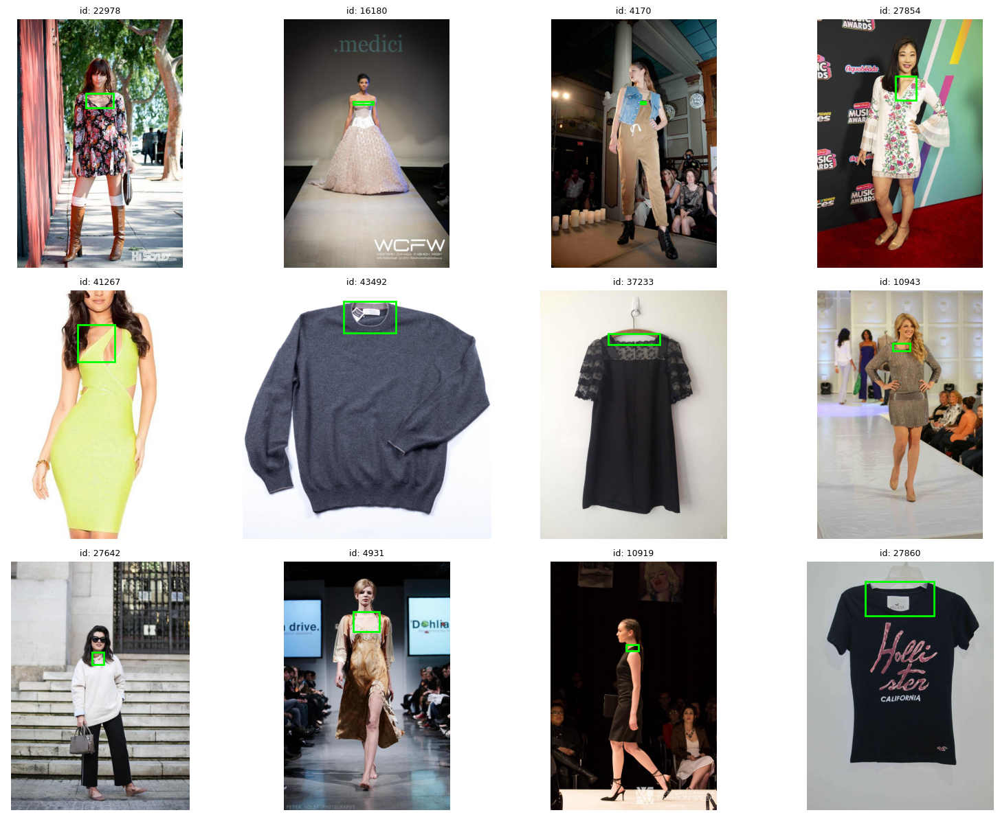

Saved: figures/phase2_sample_boxes_fixed.png


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import random

random.seed(7)
sample = random.sample(splits["train"], 12)

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

for ax, item in zip(axes, sample):
    ex = ds_train[item["hf_index"]] if item["hf_split"] == "train" else ds_val[item["hf_index"]]
    img = ex["image"]
    x, y, w, h = item["neckline_bbox_xywh"]

    ax.imshow(img)
    rect = patches.Rectangle((x, y), w, h, linewidth=2, edgecolor='lime', facecolor='none')
    ax.add_patch(rect)
    ax.set_title(f"id: {item['image_id']}", fontsize=9)
    ax.axis('off')

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/FYP_Neckline/figures/phase2_sample_boxes_fixed.png', dpi=150)
plt.show()
print("Saved: figures/phase2_sample_boxes_fixed.png")

In [ ]:
import os

zip_path = '/content/drive/MyDrive/FYP_Neckline/data/raw/kurta_images_and_annotations.zip'

if os.path.exists(zip_path):
    size_mb = os.path.getsize(zip_path) / (1024 * 1024)
    print(f"File found! Size: {size_mb:.1f} MB")
else:
    print("File NOT found — check the filename/path")

File found! Size: 745.9 MB


In [ ]:
import zipfile
import os

zip_path = '/content/drive/MyDrive/FYP_Neckline/data/raw/kurta_images_and_annotations.zip'
extract_path = '/content/drive/MyDrive/FYP_Neckline/data/raw/kouture_images'

os.makedirs(extract_path, exist_ok=True)
with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall(extract_path)

print("Extracted to:", extract_path)

# Find the FINAL_KURTA folder inside, wherever it landed
for root, dirs, files in os.walk(extract_path):
    print(root, "->", len(files), "files")

Extracted to: /content/drive/MyDrive/FYP_Neckline/data/raw/kouture_images
/content/drive/MyDrive/FYP_Neckline/data/raw/kouture_images -> 0 files
/content/drive/MyDrive/FYP_Neckline/data/raw/kouture_images/FINAL_KURTA -> 20002 files


In [ ]:
import os

folder = '/content/drive/MyDrive/FYP_Neckline/data/raw/kouture_images/FINAL_KURTA'
files = os.listdir(folder)

# Separate by extension
from collections import Counter
ext_counts = Counter(os.path.splitext(f)[1].lower() for f in files)
print("File types found:")
for ext, count in ext_counts.most_common():
    print(f"  {ext}: {count}")

# Show non-image files specifically (likely the annotation file)
non_images = [f for f in files if not f.lower().endswith(('.jpg', '.jpeg', '.png'))]
print("\nNon-image files (likely annotations):")
for f in non_images:
    print(" ", f)

File types found:
  .jpg: 20000
  .csv: 2

Non-image files (likely annotations):
  FINAL.csv
  _annotations.csv


In [ ]:
import pandas as pd

folder = '/content/drive/MyDrive/FYP_Neckline/data/raw/kouture_images/FINAL_KURTA'

final_df = pd.read_csv(f'{folder}/FINAL.csv')
print("FINAL.csv shape:", final_df.shape)
print("FINAL.csv columns:", list(final_df.columns))
print(final_df.head())
print()
print("="*50)
print()

ann_df = pd.read_csv(f'{folder}/_annotations.csv')
print("_annotations.csv shape:", ann_df.shape)
print("_annotations.csv columns:", list(ann_df.columns))
print(ann_df.head())

FINAL.csv shape: (20000, 17)
FINAL.csv columns: ['title', 'name', 'price', 'colour', 'fabric', 'fabric_purity', 'sleeve_styling', 'productId', 'images', 'Sleeve Length', 'Shape', 'Neck', 'Print or Pattern Type', 'Design Styling', 'Slit Detail', 'Length', 'Hemline']
      title                                               name  price  \
0     Anouk  Women Red &amp; White Ikat Printed Pure Cotton...    559   
1    SCAKHI                   Women Red Printed Straight Kurta    539   
2    FASHOR      Geometric Embroidered Sequinned Pleated Kurta    969   
3     Anouk  Ethnic Motifs Printed Halter Neck Pure Cotton ...    591   
4  Indo Era    Women Ethnic Motifs Embroidered Sequinned Kurta   1329   

     colour         fabric fabric_purity sleeve_styling  productId  \
0       Red         Cotton          Pure        Regular   17095292   
1       Red  Viscose Rayon          Pure        Regular   20036286   
2  Burgundy  Viscose Rayon          Pure        Regular   25889766   
3     Green    

In [ ]:
import os
import pandas as pd

folder = '/content/drive/MyDrive/FYP_Neckline/data/raw/kouture_images/FINAL_KURTA'
final_df = pd.read_csv(f'{folder}/FINAL.csv')

image_files = [f for f in os.listdir(folder) if f.lower().endswith('.jpg')]
image_ids = set(os.path.splitext(f)[0] for f in image_files)

product_ids = set(final_df['productId'].astype(str))

matched = image_ids & product_ids
print(f"Local image files: {len(image_ids)}")
print(f"productIds in FINAL.csv: {len(product_ids)}")
print(f"Matched (filename == productId): {len(matched)}")
print(f"Match rate: {100*len(matched)/len(image_ids):.1f}%")

# Neckline type distribution across the full 20,000
print("\nNeckline type distribution (FINAL.csv):")
print(final_df['Neck'].value_counts())

Local image files: 20000
productIds in FINAL.csv: 20000
Matched (filename == productId): 20000
Match rate: 100.0%

Neckline type distribution (FINAL.csv):
Neck
Round Neck         10423
Mandarin Collar     4085
V-Neck              2034
Keyhole Neck         844
Band Collar          530
Boat Neck            530
Tie-Up Neck          467
Shirt Collar         409
Square Neck          171
Shoulder Straps      149
Sweetheart Neck      145
Scoop Neck           139
Halter Neck           29
Stylised Neck         25
Off-Shoulder          13
Cowl Neck              3
Shawl Neck             3
Name: count, dtype: int64


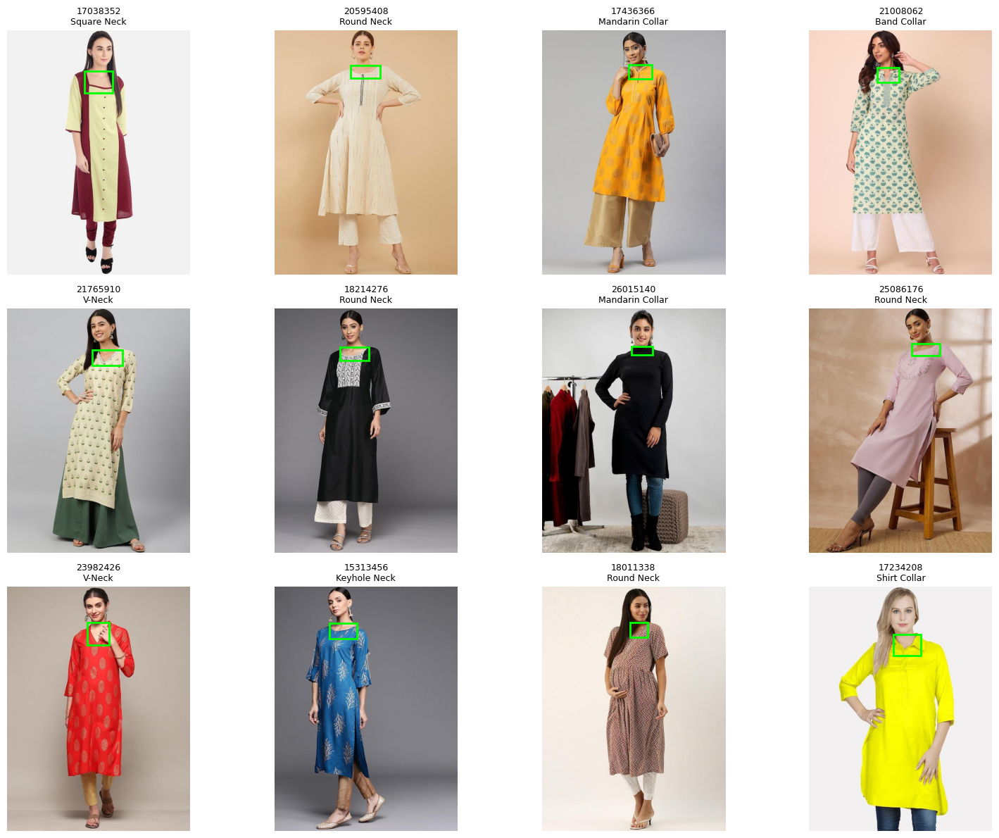

Saved: figures/phase2_kouture_sample_boxes.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import random

folder = '/content/drive/MyDrive/FYP_Neckline/data/raw/kouture_images/FINAL_KURTA'
ann_df = pd.read_csv(f'{folder}/_annotations.csv')
final_df = pd.read_csv(f'{folder}/FINAL.csv')
final_df['productId'] = final_df['productId'].astype(str)

neck_boxes = ann_df[ann_df['class'] == 'Neck'].copy()
neck_boxes['productId'] = neck_boxes['filename'].str.split('_jpg.rf.').str[0]

random.seed(7)
sample = neck_boxes.sample(12, random_state=7)

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

for ax, (_, row) in zip(axes, sample.iterrows()):
    pid = row['productId']
    img_path = f'{folder}/{pid}.jpg'
    img = Image.open(img_path)

    x, y = row['xmin'], row['ymin']
    w, h = row['xmax'] - row['xmin'], row['ymax'] - row['ymin']

    neck_type = final_df.loc[final_df['productId'] == pid, 'Neck']
    neck_type = neck_type.values[0] if len(neck_type) > 0 else "unknown"

    ax.imshow(img)
    rect = patches.Rectangle((x, y), w, h, linewidth=2, edgecolor='lime', facecolor='none')
    ax.add_patch(rect)
    ax.set_title(f"{pid}\n{neck_type}", fontsize=9)
    ax.axis('off')

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/FYP_Neckline/figures/phase2_kouture_sample_boxes.png', dpi=150)
plt.show()
print("Saved: figures/phase2_kouture_sample_boxes.png")

In [ ]:
!pip install -q ultralytics

import os

# YOLO folder structure banate hain
yolo_base = '/content/drive/MyDrive/FYP_Neckline/data/yolo_dataset'
for split in ['train', 'val', 'test']:
    os.makedirs(f'{yolo_base}/images/{split}', exist_ok=True)
    os.makedirs(f'{yolo_base}/labels/{split}', exist_ok=True)

print("YOLO folder structure ready at:", yolo_base)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.5/46.5 kB 474.3 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.1/78.1 kB 7.4 MB/s eta 0:00:00
YOLO folder structure ready at: /content/drive/MyDrive/FYP_Neckline/data/yolo_dataset


In [ ]:
# Reload ds_train/ds_val if a session restart cleared them
try:
    ds_train
    ds_val
except NameError:
    from datasets import load_dataset
    ds_train = load_dataset("detection-datasets/fashionpedia", split="train")
    ds_val = load_dataset("detection-datasets/fashionpedia", split="val")

import json
from PIL import Image

yolo_base = '/content/drive/MyDrive/FYP_Neckline/data/yolo_dataset'

for split_name in ['train', 'val', 'test']:
    with open(f'/content/drive/MyDrive/FYP_Neckline/data/splits/{split_name}_manifest.json') as f:
        manifest = json.load(f)

    print(f"Converting {split_name}: {len(manifest)} images...")

    for i, item in enumerate(manifest):
        ds = ds_train if item['hf_split'] == 'train' else ds_val
        ex = ds[item['hf_index']]
        img = ex['image']

        img_w, img_h = item['width'], item['height']
        x, y, w, h = item['neckline_bbox_xywh']

        # YOLO format: normalized center_x, center_y, width, height
        cx = (x + w / 2) / img_w
        cy = (y + h / 2) / img_h
        nw = w / img_w
        nh = h / img_h

        img_filename = f"fp_{item['image_id']}.jpg"
        label_filename = f"fp_{item['image_id']}.txt"

        img.convert('RGB').save(f'{yolo_base}/images/{split_name}/{img_filename}')
        with open(f'{yolo_base}/labels/{split_name}/{label_filename}', 'w') as lf:
            lf.write(f"0 {cx:.6f} {cy:.6f} {nw:.6f} {nh:.6f}\n")

        if (i + 1) % 5000 == 0:
            print(f"  {i+1}/{len(manifest)} done")

    print(f"{split_name} complete.\n")

print("Fashionpedia -> YOLO conversion done.")

README.md:   0%|          | 0.00/5.22k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/1.78k [00:00<?, ?B/s]

data/train-00000-of-00007-fe108070118553(…): reconstructing file:   0%|          |  0.00B /  482MB            

data/train-00000-of-00007-fe108070118553(…): downloading bytes:           |  0.00B            

data/train-00001-of-00007-f41a5a9c38c900(…): reconstructing file:   0%|          |  0.00B /  480MB            

...

data/val-00000-of-00001-0b29e85429788213(…): reconstructing file:   0%|          |  0.00B / 84.8MB            

data/val-00000-of-00001-0b29e85429788213(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/45623 [00:00<?, ? examples/s]

Generating val split:   0%|          | 0/1158 [00:00<?, ? examples/s]

Converting train: 27244 images...
  5000/27244 done
  10000/27244 done
  15000/27244 done
  20000/27244 done
  25000/27244 done
train complete.

Converting val: 3405 images...
val complete.

Converting test: 3406 images...
test complete.

Fashionpedia -> YOLO conversion done.


In [ ]:
import pandas as pd
from PIL import Image
import random

folder = '/content/drive/MyDrive/FYP_Neckline/data/raw/kouture_images/FINAL_KURTA'
yolo_base = '/content/drive/MyDrive/FYP_Neckline/data/yolo_dataset'

ann_df = pd.read_csv(f'{folder}/_annotations.csv')
neck_boxes = ann_df[ann_df['class'] == 'Neck'].copy()
neck_boxes['productId'] = neck_boxes['filename'].str.split('_jpg.rf.').str[0]

# 80/10/10 split, same seed for consistency
random.seed(42)
pids = neck_boxes['productId'].unique().tolist()
random.shuffle(pids)

n = len(pids)
train_end = int(n * 0.8)
val_end = int(n * 0.9)
split_map = {}
for pid in pids[:train_end]:
    split_map[pid] = 'train'
for pid in pids[train_end:val_end]:
    split_map[pid] = 'val'
for pid in pids[val_end:]:
    split_map[pid] = 'test'

print(f"Kouture split: train={train_end}, val={val_end-train_end}, test={n-val_end}")

for _, row in neck_boxes.iterrows():
    pid = row['productId']
    split_name = split_map[pid]

    img_path = f'{folder}/{pid}.jpg'
    img = Image.open(img_path).convert('RGB')
    img_w, img_h = img.size

    x = row['xmin']
    y = row['ymin']
    w = row['xmax'] - row['xmin']
    h = row['ymax'] - row['ymin']

    cx = (x + w / 2) / img_w
    cy = (y + h / 2) / img_h
    nw = w / img_w
    nh = h / img_h

    img_filename = f"kt_{pid}.jpg"
    label_filename = f"kt_{pid}.txt"

    img.save(f'{yolo_base}/images/{split_name}/{img_filename}')
    with open(f'{yolo_base}/labels/{split_name}/{label_filename}', 'w') as lf:
        lf.write(f"0 {cx:.6f} {cy:.6f} {nw:.6f} {nh:.6f}\n")

print("Kouture -> YOLO conversion done.")

Kouture split: train=1596, val=200, test=200
Kouture -> YOLO conversion done.


In [ ]:
yaml_content = """
path: /content/drive/MyDrive/FYP_Neckline/data/yolo_dataset
train: images/train
val: images/val
test: images/test

names:
  0: neckline
"""

yaml_path = '/content/drive/MyDrive/FYP_Neckline/data/yolo_dataset/neckline.yaml'
with open(yaml_path, 'w') as f:
    f.write(yaml_content)

print("Saved:", yaml_path)

# Quick sanity check — count actual files
import os
for split in ['train', 'val', 'test']:
    n_img = len(os.listdir(f'/content/drive/MyDrive/FYP_Neckline/data/yolo_dataset/images/{split}'))
    n_lbl = len(os.listdir(f'/content/drive/MyDrive/FYP_Neckline/data/yolo_dataset/labels/{split}'))
    print(f"{split}: {n_img} images, {n_lbl} labels")

Saved: /content/drive/MyDrive/FYP_Neckline/data/yolo_dataset/neckline.yaml
train: 28840 images, 28840 labels
val: 3605 images, 3605 labels
test: 3606 images, 3606 labels


In [ ]:
import os

path_to_check = '/content/drive/MyDrive/FYP_Neckline/data/yolo_dataset'
print("Folder exists:", os.path.exists(path_to_check))

if os.path.exists(path_to_check):
    print("Contents:", os.listdir(path_to_check))
else:
    print("Checking parent folder...")
    print(os.listdir('/content/drive/MyDrive/FYP_Neckline/data'))

Folder exists: True
Contents: ['images', 'labels']


In [ ]:
yaml_content = """
path: /content/drive/MyDrive/FYP_Neckline/data/yolo_dataset
train: images/train
val: images/val
test: images/test

names:
  0: neckline
"""

yaml_path = '/content/drive/MyDrive/FYP_Neckline/data/yolo_dataset/neckline.yaml'
with open(yaml_path, 'w') as f:
    f.write(yaml_content)

print("Saved:", yaml_path)
print("Exists now:", os.path.exists(yaml_path))

Saved: /content/drive/MyDrive/FYP_Neckline/data/yolo_dataset/neckline.yaml
Exists now: True


In [ ]:
import shutil, os
from concurrent.futures import ThreadPoolExecutor
import time

src = '/content/drive/MyDrive/FYP_Neckline/data/yolo_dataset'
dst = '/content/yolo_dataset_local'

def copy_folder(split, kind):
    src_dir = f'{src}/{kind}/{split}'
    dst_dir = f'{dst}/{kind}/{split}'
    os.makedirs(dst_dir, exist_ok=True)
    files = os.listdir(src_dir)
    def copy_one(f):
        shutil.copy2(f'{src_dir}/{f}', f'{dst_dir}/{f}')
    with ThreadPoolExecutor(max_workers=16) as ex:
        list(ex.map(copy_one, files))
    print(f"{kind}/{split}: {len(files)} files copied")

start = time.time()
for kind in ['images', 'labels']:
    for split in ['train', 'val', 'test']:
        copy_folder(split, kind)

print(f"\nTotal time: {(time.time()-start)/60:.1f} minutes")

images/train: 16556 files copied
images/val: 0 files copied
images/test: 0 files copied
labels/train: 16555 files copied
labels/val: 0 files copied
labels/test: 0 files copied

Total time: 9.8 minutes


In [ ]:
import os

base = '/content/drive/MyDrive/FYP_Neckline/data/yolo_dataset'
for kind in ['images', 'labels']:
    for split in ['train', 'val', 'test']:
        path = f'{base}/{kind}/{split}'
        count = len(os.listdir(path))
        print(f"{kind}/{split}: {count} files")

images/train: 16556 files
images/val: 0 files
images/test: 0 files
labels/train: 16555 files
labels/val: 0 files
labels/test: 0 files


In [ ]:
import os
folder = '/content/drive/MyDrive/FYP_Neckline/data/raw/kouture_images/FINAL_KURTA'
files = os.listdir(folder)
print("Kouture raw files found:", len(files))

Kouture raw files found: 20002


In [ ]:
from datasets import load_dataset

ds_train = load_dataset("detection-datasets/fashionpedia", split="train")
ds_val = load_dataset("detection-datasets/fashionpedia", split="val")
print("Fashionpedia reloaded.")

README.md:   0%|          | 0.00/5.22k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/1.78k [00:00<?, ?B/s]

data/train-00000-of-00007-fe108070118553(…): reconstructing file:   0%|          |  0.00B /  482MB            

data/train-00000-of-00007-fe108070118553(…): downloading bytes:           |  0.00B            

data/train-00001-of-00007-f41a5a9c38c900(…): reconstructing file:   0%|          |  0.00B /  480MB            

...

data/val-00000-of-00001-0b29e85429788213(…): reconstructing file:   0%|          |  0.00B / 84.8MB            

data/val-00000-of-00001-0b29e85429788213(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/45623 [00:00<?, ? examples/s]

Generating val split:   0%|          | 0/1158 [00:00<?, ? examples/s]

Fashionpedia reloaded.


In [ ]:
import json, os
from PIL import Image

local_base = '/content/yolo_dataset_local'
for split in ['train', 'val', 'test']:
    os.makedirs(f'{local_base}/images/{split}', exist_ok=True)
    os.makedirs(f'{local_base}/labels/{split}', exist_ok=True)

for split_name in ['train', 'val', 'test']:
    with open(f'/content/drive/MyDrive/FYP_Neckline/data/splits/{split_name}_manifest.json') as f:
        manifest = json.load(f)

    print(f"Converting {split_name}: {len(manifest)} images...")

    for i, item in enumerate(manifest):
        ds = ds_train if item['hf_split'] == 'train' else ds_val
        ex = ds[item['hf_index']]
        img = ex['image']

        img_w, img_h = item['width'], item['height']
        x, y, w, h = item['neckline_bbox_xywh']

        cx = (x + w / 2) / img_w
        cy = (y + h / 2) / img_h
        nw = w / img_w
        nh = h / img_h

        img_filename = f"fp_{item['image_id']}.jpg"
        label_filename = f"fp_{item['image_id']}.txt"

        img.convert('RGB').save(f'{local_base}/images/{split_name}/{img_filename}')
        with open(f'{local_base}/labels/{split_name}/{label_filename}', 'w') as lf:
            lf.write(f"0 {cx:.6f} {cy:.6f} {nw:.6f} {nh:.6f}\n")

        if (i + 1) % 5000 == 0:
            print(f"  {i+1}/{len(manifest)} done")

    print(f"{split_name} complete.\n")

print("Fashionpedia -> local YOLO conversion done.")

Converting train: 27244 images...
  5000/27244 done
  10000/27244 done
  15000/27244 done
  20000/27244 done
  25000/27244 done
train complete.

Converting val: 3405 images...
val complete.

Converting test: 3406 images...
test complete.

Fashionpedia -> local YOLO conversion done.


In [ ]:
import pandas as pd
import shutil, os
from concurrent.futures import ThreadPoolExecutor
import time

folder = '/content/drive/MyDrive/FYP_Neckline/data/raw/kouture_images/FINAL_KURTA'
local_kouture = '/content/kouture_local'
os.makedirs(local_kouture, exist_ok=True)

ann_df = pd.read_csv(f'{folder}/_annotations.csv')
neck_boxes = ann_df[ann_df['class'] == 'Neck'].copy()
neck_boxes['productId'] = neck_boxes['filename'].str.split('_jpg.rf.').str[0]

pids_needed = neck_boxes['productId'].unique().tolist()
print(f"Copying {len(pids_needed)} images to local disk...")

def copy_one(pid):
    shutil.copy2(f'{folder}/{pid}.jpg', f'{local_kouture}/{pid}.jpg')

start = time.time()
with ThreadPoolExecutor(max_workers=16) as ex:
    list(ex.map(copy_one, pids_needed))

print(f"Done. Copied {len(os.listdir(local_kouture))} files in {(time.time()-start)/60:.1f} min")

Copying 1996 images to local disk...
Done. Copied 1996 files in 0.7 min


In [ ]:
from PIL import Image

local_kouture = '/content/kouture_local'
local_base = '/content/yolo_dataset_local'

for _, row in neck_boxes.iterrows():
    pid = row['productId']
    split_name = split_map[pid]

    img_path = f'{local_kouture}/{pid}.jpg'
    img = Image.open(img_path).convert('RGB')
    img_w, img_h = img.size

    x, y = row['xmin'], row['ymin']
    w, h = row['xmax'] - row['xmin'], row['ymax'] - row['ymin']

    cx = (x + w / 2) / img_w
    cy = (y + h / 2) / img_h
    nw = w / img_w
    nh = h / img_h

    img.save(f'{local_base}/images/{split_name}/kt_{pid}.jpg')
    with open(f'{local_base}/labels/{split_name}/kt_{pid}.txt', 'w') as lf:
        lf.write(f"0 {cx:.6f} {cy:.6f} {nw:.6f} {nh:.6f}\n")

print("Kouture -> local YOLO conversion done.")

Kouture -> local YOLO conversion done.


In [ ]:
yaml_content = """
path: /content/yolo_dataset_local
train: images/train
val: images/val
test: images/test

names:
  0: neckline
"""
yaml_path = '/content/yolo_dataset_local/neckline.yaml'
with open(yaml_path, 'w') as f:
    f.write(yaml_content)
print("Saved:", yaml_path)

Saved: /content/yolo_dataset_local/neckline.yaml


In [ ]:
import os

for split in ['train', 'val', 'test']:
    n_img = len(os.listdir(f'/content/yolo_dataset_local/images/{split}'))
    n_lbl = len(os.listdir(f'/content/yolo_dataset_local/labels/{split}'))
    print(f"{split}: {n_img} images, {n_lbl} labels")

train: 28840 images, 28840 labels
val: 3605 images, 3605 labels
test: 3606 images, 3606 labels


In [ ]:
from ultralytics import YOLO

model = YOLO('yolov8n.pt')

results = model.train(
    data='/content/yolo_dataset_local/neckline.yaml',
    epochs=30,
    imgsz=640,
    batch=16,
    project='/content/drive/MyDrive/FYP_Neckline/checkpoints',
    name='neckline_yolov8n',
    patience=10,
)

ModuleNotFoundError: No module named 'ultralytics'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
checkpoints_base = '/content/drive/MyDrive/FYP_Neckline/checkpoints'
print("Runs found:", os.listdir(checkpoints_base))

Mounted at /content/drive
Runs found: ['neckline_yolov8n', 'neckline_yolov8n-2', 'neckline_yolov8n-3']


In [ ]:
import os

latest_run = '/content/drive/MyDrive/FYP_Neckline/checkpoints/neckline_yolov8n-3'
print("Contents:", os.listdir(latest_run))

weights_path = f'{latest_run}/weights'
if os.path.exists(weights_path):
    print("Weights folder contents:", os.listdir(weights_path))
else:
    print("No weights folder found")

Contents: ['weights', 'args.yaml', 'labels.jpg', 'train_batch0.jpg', 'train_batch1.jpg', 'train_batch2.jpg', 'results.csv']
Weights folder contents: ['best.pt', 'last.pt']


In [ ]:
import pandas as pd

results_df = pd.read_csv(f'{latest_run}/results.csv')
print("Epochs completed:", len(results_df))
print(results_df.tail())

Epochs completed: 8
   epoch     time  train/box_loss  train/cls_loss  train/dfl_loss  \
3      4  2194.70         1.74158         1.37378         1.31198   
4      5  2723.81         1.65413         1.27075         1.26891   
5      6  3251.57         1.59890         1.21766         1.23938   
6      7  3774.56         1.55475         1.16906         1.21071   
7      8  4294.84         1.53267         1.13726         1.19649   

   metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  \
3               0.69345            0.60615           0.66721   
4               0.72800            0.64438           0.70394   
5               0.75057            0.64799           0.72122   
6               0.77469            0.66796           0.74340   
7               0.77150            0.69214           0.75730   

   metrics/mAP50-95(B)  val/box_loss  val/cls_loss  val/dfl_loss   lr/pg0  \
3              0.36750       1.56979       1.23057       1.27665  0.02703   
4              0.40137    

In [ ]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.5/46.5 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 39.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.1/78.1 kB 9.2 MB/s eta 0:00:00


In [ ]:
from datasets import load_dataset

ds_train = load_dataset("detection-datasets/fashionpedia", split="train")
ds_val = load_dataset("detection-datasets/fashionpedia", split="val")
print("Fashionpedia reloaded.")

README.md:   0%|          | 0.00/5.22k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/1.78k [00:00<?, ?B/s]

data/train-00000-of-00007-fe108070118553(…): reconstructing file:   0%|          |  0.00B /  482MB            

data/train-00000-of-00007-fe108070118553(…): downloading bytes:           |  0.00B            

data/train-00001-of-00007-f41a5a9c38c900(…): reconstructing file:   0%|          |  0.00B /  480MB            

...

data/val-00000-of-00001-0b29e85429788213(…): reconstructing file:   0%|          |  0.00B / 84.8MB            

data/val-00000-of-00001-0b29e85429788213(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/45623 [00:00<?, ? examples/s]

Generating val split:   0%|          | 0/1158 [00:00<?, ? examples/s]

Fashionpedia reloaded.


In [ ]:
import json, os
from PIL import Image

local_base = '/content/yolo_dataset_local'
for split in ['train', 'val', 'test']:
    os.makedirs(f'{local_base}/images/{split}', exist_ok=True)
    os.makedirs(f'{local_base}/labels/{split}', exist_ok=True)

for split_name in ['train', 'val', 'test']:
    with open(f'/content/drive/MyDrive/FYP_Neckline/data/splits/{split_name}_manifest.json') as f:
        manifest = json.load(f)
    print(f"Converting {split_name}: {len(manifest)} images...")
    for i, item in enumerate(manifest):
        ds = ds_train if item['hf_split'] == 'train' else ds_val
        ex = ds[item['hf_index']]
        img = ex['image']
        img_w, img_h = item['width'], item['height']
        x, y, w, h = item['neckline_bbox_xywh']
        cx = (x + w / 2) / img_w
        cy = (y + h / 2) / img_h
        nw = w / img_w
        nh = h / img_h
        img.convert('RGB').save(f'{local_base}/images/{split_name}/fp_{item["image_id"]}.jpg')
        with open(f'{local_base}/labels/{split_name}/fp_{item["image_id"]}.txt', 'w') as lf:
            lf.write(f"0 {cx:.6f} {cy:.6f} {nw:.6f} {nh:.6f}\n")
        if (i + 1) % 5000 == 0:
            print(f"  {i+1}/{len(manifest)} done")
    print(f"{split_name} complete.\n")
print("Fashionpedia -> local YOLO conversion done.")

Converting train: 27244 images...
  5000/27244 done
  10000/27244 done
  15000/27244 done
  20000/27244 done
  25000/27244 done
train complete.

Converting val: 3405 images...
val complete.

Converting test: 3406 images...
test complete.

Fashionpedia -> local YOLO conversion done.


In [ ]:
import pandas as pd, shutil
from concurrent.futures import ThreadPoolExecutor
import time

folder = '/content/drive/MyDrive/FYP_Neckline/data/raw/kouture_images/FINAL_KURTA'
local_kouture = '/content/kouture_local'
os.makedirs(local_kouture, exist_ok=True)

ann_df = pd.read_csv(f'{folder}/_annotations.csv')
neck_boxes = ann_df[ann_df['class'] == 'Neck'].copy()
neck_boxes['productId'] = neck_boxes['filename'].str.split('_jpg.rf.').str[0]

pids_needed = neck_boxes['productId'].unique().tolist()
def copy_one(pid):
    shutil.copy2(f'{folder}/{pid}.jpg', f'{local_kouture}/{pid}.jpg')

start = time.time()
with ThreadPoolExecutor(max_workers=16) as ex:
    list(ex.map(copy_one, pids_needed))
print(f"Copied {len(os.listdir(local_kouture))} files in {(time.time()-start)/60:.1f} min")

Copied 1996 files in 1.7 min


In [ ]:
import random
from PIL import Image

random.seed(42)
pids = neck_boxes['productId'].unique().tolist()
random.shuffle(pids)
n = len(pids)
train_end = int(n * 0.8)
val_end = int(n * 0.9)
split_map = {}
for pid in pids[:train_end]: split_map[pid] = 'train'
for pid in pids[train_end:val_end]: split_map[pid] = 'val'
for pid in pids[val_end:]: split_map[pid] = 'test'

for _, row in neck_boxes.iterrows():
    pid = row['productId']
    split_name = split_map[pid]
    img = Image.open(f'{local_kouture}/{pid}.jpg').convert('RGB')
    img_w, img_h = img.size
    x, y = row['xmin'], row['ymin']
    w, h = row['xmax'] - row['xmin'], row['ymax'] - row['ymin']
    cx, cy = (x + w/2)/img_w, (y + h/2)/img_h
    nw, nh = w/img_w, h/img_h
    img.save(f'/content/yolo_dataset_local/images/{split_name}/kt_{pid}.jpg')
    with open(f'/content/yolo_dataset_local/labels/{split_name}/kt_{pid}.txt', 'w') as lf:
        lf.write(f"0 {cx:.6f} {cy:.6f} {nw:.6f} {nh:.6f}\n")
print("Kouture -> local YOLO conversion done.")

Kouture -> local YOLO conversion done.


In [ ]:
yaml_content = """
path: /content/yolo_dataset_local
train: images/train
val: images/val
test: images/test

names:
  0: neckline
"""
with open('/content/yolo_dataset_local/neckline.yaml', 'w') as f:
    f.write(yaml_content)
print("YAML saved")

YAML saved


In [ ]:
from ultralytics import YOLO

model = YOLO('/content/drive/MyDrive/FYP_Neckline/checkpoints/neckline_yolov8n-3/weights/last.pt')
results = model.train(resume=True)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
New https://pypi.org/project/ultralytics/8.4.155 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.154 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_dataset_local/neckline.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=Fal

In [ ]:
from ultralytics import YOLO

model = YOLO('/content/drive/MyDrive/FYP_Neckline/checkpoints/neckline_yolov8n-3/weights/best.pt')

test_results = model.val(
    data='/content/yolo_dataset_local/neckline.yaml',
    split='test'
)

print("\nTest set results:")
print(f"Precision: {test_results.box.p[0]:.3f}")
print(f"Recall: {test_results.box.r[0]:.3f}")
print(f"mAP50: {test_results.box.map50:.3f}")
print(f"mAP50-95: {test_results.box.map:.3f}")

Ultralytics 8.4.154 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 42.7±17.7 MB/s, size: 80.9 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/yolo_dataset_local/labels/test... 3606 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3606/3606 507.0it/s 7.1s
val: New cache created: /content/yolo_dataset_local/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 226/226 6.4it/s 35.4s
                   all       3606       3606      0.824      0.747      0.814      0.533
Speed: 1.1ms preprocess, 3.0ms inference, 0.0ms loss, 1.3ms postprocess per image
Results saved to /content/runs/detect/val

Test set results:
Precision: 0.824
Recall: 0.74

In [ ]:
from ultralytics import YOLO
import pandas as pd
import os

model = YOLO('/content/drive/MyDrive/FYP_Neckline/checkpoints/neckline_yolov8n-3/weights/best.pt')

local_kouture = '/content/kouture_local'
folder = '/content/drive/MyDrive/FYP_Neckline/data/raw/kouture_images/FINAL_KURTA'
final_df = pd.read_csv(f'{folder}/FINAL.csv')
final_df['productId'] = final_df['productId'].astype(str)

# Fall back to reading from Drive if the local image cache is empty (slower but works)
if not os.path.exists(local_kouture) or len(os.listdir(local_kouture)) == 0:
    local_kouture = folder
    print("Using Drive path directly (local cache missing this session)")

results_list = []

for i, row in final_df.iterrows():
    pid = row['productId']
    img_path = f'{local_kouture}/{pid}.jpg'
    if not os.path.exists(img_path):
        continue

    pred = model.predict(img_path, verbose=False)[0]

    if len(pred.boxes) == 0:
        continue  # koi neckline detect nahi hui is image mein

    # Sabse zyada confidence wala box lo
    best_idx = pred.boxes.conf.argmax().item()
    box = pred.boxes.xywhn[best_idx].tolist()  # normalized [cx, cy, w, h]
    conf = pred.boxes.conf[best_idx].item()

    width_norm = box[2]
    depth_norm = box[3]
    openness_ratio = width_norm / depth_norm if depth_norm > 0 else None

    results_list.append({
        'productId': pid,
        'neckline_type': row['Neck'],
        'width_norm': width_norm,
        'depth_norm': depth_norm,
        'openness_ratio': openness_ratio,
        'confidence': conf,
    })

    if (i + 1) % 2000 == 0:
        print(f"{i+1}/{len(final_df)} processed, {len(results_list)} with detections so far")

geo_df = pd.DataFrame(results_list)
print(f"\nTotal images processed: {len(final_df)}")
print(f"Total with successful detection: {len(geo_df)}")

geo_df.to_csv('/content/drive/MyDrive/FYP_Neckline/results/geometry_features.csv', index=False)
print("Saved: results/geometry_features.csv")

print("\nSample rows:")
print(geo_df.head(10))

16000/20000 processed, 1614 with detections so far

Total images processed: 20000
Total with successful detection: 1992
Saved: results/geometry_features.csv

Sample rows:
  productId    neckline_type  width_norm  depth_norm  openness_ratio  \
0  25889766       Round Neck    0.140012    0.056046        2.498133   
1  13462626  Mandarin Collar    0.120411    0.067305        1.789038   
2  24967982       Round Neck    0.103089    0.038589        2.671434   
3  25259968     Keyhole Neck    0.095553    0.025479        3.750279   
4  19604244       Round Neck    0.137189    0.067233        2.040500   
5  11862394           V-Neck    0.105081    0.076424        1.374982   
6  20363536       Round Neck    0.141442    0.052419        2.698326   
7  21093180       Round Neck    0.125456    0.044707        2.806166   
8  25179826  Mandarin Collar    0.096471    0.033732        2.859946   
9  17080376  Mandarin Collar    0.107278    0.044230        2.425477   

   confidence  
0    0.770950  
1   

In [ ]:
import pandas as pd

folder = '/content/drive/MyDrive/FYP_Neckline/data/raw/kouture_images/FINAL_KURTA'
ann_df = pd.read_csv(f'{folder}/_annotations.csv')
neck_boxes = ann_df[ann_df['class'] == 'Neck'].copy()
neck_boxes['productId'] = neck_boxes['filename'].str.split('_jpg.rf.').str[0]
annotated_pids = set(neck_boxes['productId'])

geo_df = pd.read_csv('/content/drive/MyDrive/FYP_Neckline/results/geometry_features.csv')
geo_df['productId'] = geo_df['productId'].astype(str)
detected_pids = set(geo_df['productId'])

overlap = annotated_pids & detected_pids
print(f"Annotated (seen in training): {len(annotated_pids)}")
print(f"Detected now: {len(detected_pids)}")
print(f"Overlap: {len(overlap)}")
print(f"Detected images that were NEVER in training annotations: {len(detected_pids - annotated_pids)}")

Annotated (seen in training): 1996
Detected now: 1992
Overlap: 1992
Detected images that were NEVER in training annotations: 0


In [ ]:
from ultralytics import YOLO
import pandas as pd
import os

model = YOLO('/content/drive/MyDrive/FYP_Neckline/checkpoints/neckline_yolov8n-3/weights/best.pt')

folder = '/content/drive/MyDrive/FYP_Neckline/data/raw/kouture_images/FINAL_KURTA'
final_df = pd.read_csv(f'{folder}/FINAL.csv')
final_df['productId'] = final_df['productId'].astype(str)

# List of images never seen during detector training
unseen_pids = set(final_df['productId']) - annotated_pids
sample_unseen = list(unseen_pids)[:20]

print("Testing 20 unseen images with very low confidence threshold (0.01)...\n")

for pid in sample_unseen:
    img_path = f'{folder}/{pid}.jpg'
    pred = model.predict(img_path, conf=0.01, verbose=False)[0]
    n_boxes = len(pred.boxes)
    max_conf = pred.boxes.conf.max().item() if n_boxes > 0 else 0
    print(f"{pid}: {n_boxes} boxes found, max confidence: {max_conf:.3f}")

Testing 20 unseen images with very low confidence threshold (0.01)...

19310182: 3 boxes found, max confidence: 0.475
22751470: 1 boxes found, max confidence: 0.803
24581920: 1 boxes found, max confidence: 0.848
26425618: 2 boxes found, max confidence: 0.561
24003338: 1 boxes found, max confidence: 0.803
23439218: 1 boxes found, max confidence: 0.822
16319714: 3 boxes found, max confidence: 0.580
25158292: 1 boxes found, max confidence: 0.744
26280564: 1 boxes found, max confidence: 0.783
23398014: 1 boxes found, max confidence: 0.813
14553690: 1 boxes found, max confidence: 0.763
21799342: 1 boxes found, max confidence: 0.781
24440842: 1 boxes found, max confidence: 0.792
24871644: 1 boxes found, max confidence: 0.746
12396018: 3 boxes found, max confidence: 0.406
22221814: 1 boxes found, max confidence: 0.718
23011158: 2 boxes found, max confidence: 0.709
21700054: 1 boxes found, max confidence: 0.764
21688822: 1 boxes found, max confidence: 0.798
15921962: 1 boxes found, max confide

In [ ]:
import shutil, os
from concurrent.futures import ThreadPoolExecutor
import time
import pandas as pd

folder = '/content/drive/MyDrive/FYP_Neckline/data/raw/kouture_images/FINAL_KURTA'
local_kouture_full = '/content/kouture_local_full'
os.makedirs(local_kouture_full, exist_ok=True)

final_df = pd.read_csv(f'{folder}/FINAL.csv')
final_df['productId'] = final_df['productId'].astype(str)
all_pids = final_df['productId'].tolist()

def copy_one(pid):
    src = f'{folder}/{pid}.jpg'
    dst = f'{local_kouture_full}/{pid}.jpg'
    if os.path.exists(src) and not os.path.exists(dst):
        shutil.copy2(src, dst)

print(f"Copying {len(all_pids)} images to local disk...")
start = time.time()
with ThreadPoolExecutor(max_workers=16) as ex:
    list(ex.map(copy_one, all_pids))

print(f"Done. {len(os.listdir(local_kouture_full))} files in {(time.time()-start)/60:.1f} min")

Copying 20000 images to local disk...
Done. 20000 files in 7.7 min


In [ ]:
!pip install -q ultralytics

from ultralytics import YOLO
model = YOLO('/content/drive/MyDrive/FYP_Neckline/checkpoints/neckline_yolov8n-3/weights/best.pt')
print("Model loaded")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.5/46.5 kB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 14.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.2/53.2 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.4/78.4 kB 2.7 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Model loaded


In [ ]:
from ultralytics import YOLO
model = YOLO('/content/drive/MyDrive/FYP_Neckline/checkpoints/neckline_yolov8n-3/weights/best.pt')
print("Model loaded")

Model loaded


In [ ]:
import shutil, os
from concurrent.futures import ThreadPoolExecutor
import time
import pandas as pd

folder = '/content/drive/MyDrive/FYP_Neckline/data/raw/kouture_images/FINAL_KURTA'
local_kouture_full = '/content/kouture_local_full'
os.makedirs(local_kouture_full, exist_ok=True)

final_df = pd.read_csv(f'{folder}/FINAL.csv')
final_df['productId'] = final_df['productId'].astype(str)
all_pids = final_df['productId'].tolist()

def copy_one(pid):
    src = f'{folder}/{pid}.jpg'
    dst = f'{local_kouture_full}/{pid}.jpg'
    if os.path.exists(src) and not os.path.exists(dst):
        shutil.copy2(src, dst)

print(f"Copying {len(all_pids)} images to local disk...")
start = time.time()
with ThreadPoolExecutor(max_workers=16) as ex:
    list(ex.map(copy_one, all_pids))

print(f"Done. {len(os.listdir(local_kouture_full))} files in {(time.time()-start)/60:.1f} min")

Copying 20000 images to local disk...
Done. 20000 files in 5.2 min


In [ ]:
import pandas as pd
import os

local_kouture_full = '/content/kouture_local_full'
folder = '/content/drive/MyDrive/FYP_Neckline/data/raw/kouture_images/FINAL_KURTA'
final_df = pd.read_csv(f'{folder}/FINAL.csv')
final_df['productId'] = final_df['productId'].astype(str)

results_list = []

for i, row in final_df.iterrows():
    pid = row['productId']
    img_path = f'{local_kouture_full}/{pid}.jpg'
    if not os.path.exists(img_path):
        continue

    pred = model.predict(img_path, verbose=False)[0]
    if len(pred.boxes) == 0:
        continue

    best_idx = pred.boxes.conf.argmax().item()
    box = pred.boxes.xywhn[best_idx].tolist()
    conf = pred.boxes.conf[best_idx].item()

    width_norm = box[2]
    depth_norm = box[3]
    openness_ratio = width_norm / depth_norm if depth_norm > 0 else None

    results_list.append({
        'productId': pid,
        'neckline_type': row['Neck'],
        'width_norm': width_norm,
        'depth_norm': depth_norm,
        'openness_ratio': openness_ratio,
        'confidence': conf,
    })

    if (i + 1) % 2000 == 0:
        print(f"{i+1}/{len(final_df)} processed, {len(results_list)} with detections so far")

geo_df = pd.DataFrame(results_list)
print(f"\nTotal images processed: {len(final_df)}")
print(f"Total with successful detection: {len(geo_df)}")

geo_df.to_csv('/content/drive/MyDrive/FYP_Neckline/results/geometry_features_full.csv', index=False)
print("Saved: results/geometry_features_full.csv")
print("\nDetection rate by neckline type:")
print(geo_df['neckline_type'].value_counts())

print("\nGeometry stats by neckline type:")
print(geo_df.groupby('neckline_type')[['width_norm', 'depth_norm', 'openness_ratio']].mean())

2000/20000 processed, 1996 with detections so far
4000/20000 processed, 3991 with detections so far
6000/20000 processed, 5987 with detections so far
8000/20000 processed, 7977 with detections so far
10000/20000 processed, 9971 with detections so far
12000/20000 processed, 11966 with detections so far
14000/20000 processed, 13963 with detections so far
16000/20000 processed, 15952 with detections so far
18000/20000 processed, 17939 with detections so far
20000/20000 processed, 19934 with detections so far

Total images processed: 20000
Total with successful detection: 19934
Saved: results/geometry_features_full.csv

Detection rate by neckline type:
neckline_type
Round Neck         10410
Mandarin Collar     4059
V-Neck              2029
Keyhole Neck         842
Boat Neck            529
Band Collar          527
Tie-Up Neck          464
Shirt Collar         401
Square Neck          169
Shoulder Straps      147
Sweetheart Neck      145
Scoop Neck           139
Halter Neck           29
Styl

In [ ]:
import pandas as pd

geo_df = pd.read_csv('/content/drive/MyDrive/FYP_Neckline/results/geometry_features_full.csv')

def recommend_jewellery(openness_ratio, depth_norm):
    if openness_ratio >= 3.5:
        # Very open/shallow (boat, off-shoulder)
        necklace = "Statement/short necklace or none"
        earrings = "Long jhumkas or chandelier earrings"
        reasoning = "Wide open neckline draws attention to shoulders/ears; avoid necklace competing with the neckline"
    elif openness_ratio <= 2.2:
        # Narrow/deep (V-neck, shawl, mandarin)
        necklace = "Pendant or lariat necklace"
        earrings = "Studs or small drops"
        reasoning = "Deep/narrow neckline creates a vertical line; a pendant follows and elongates it"
    else:
        # Balanced (round, most others)
        necklace = "Medium-length necklace or choker"
        earrings = "Medium drop earrings or jhumkas"
        reasoning = "Balanced neckline suits versatile jewellery lengths"

    return necklace, earrings, reasoning

geo_df[['recommended_necklace', 'recommended_earrings', 'reasoning']] = geo_df.apply(
    lambda row: pd.Series(recommend_jewellery(row['openness_ratio'], row['depth_norm'])),
    axis=1
)

geo_df.to_csv('/content/drive/MyDrive/FYP_Neckline/results/recommendations.csv', index=False)
print("Saved: results/recommendations.csv")

print("\nRecommendation distribution:")
print(geo_df['recommended_necklace'].value_counts())

print("\nSample recommendations:")
print(geo_df[['productId', 'neckline_type', 'openness_ratio', 'recommended_necklace', 'recommended_earrings']].sample(10))

Saved: results/recommendations.csv

Recommendation distribution:
recommended_necklace
Medium-length necklace or choker    14395
Pendant or lariat necklace           5038
Statement/short necklace or none      501
Name: count, dtype: int64

Sample recommendations:
       productId    neckline_type  openness_ratio  \
2229    20935786      Tie-Up Neck        3.797197   
11713   16334222     Shirt Collar        2.046971   
12927   20604080       Round Neck        3.118288   
1023    26647446       Round Neck        2.845702   
7433    22570702       Round Neck        2.870178   
10128   11100060       Round Neck        2.387421   
16012   15160652       Round Neck        2.687538   
4134    19279728  Mandarin Collar        1.459031   
3878    15603232  Mandarin Collar        1.803620   
11289   11074238       Round Neck        2.577243   

                   recommended_necklace                 recommended_earrings  
2229   Statement/short necklace or none  Long jhumkas or chandelier earrin

In [ ]:
crosstab = pd.crosstab(geo_df['neckline_type'], geo_df['recommended_necklace'])
print(crosstab)

recommended_necklace  Medium-length necklace or choker  \
neckline_type                                            
Band Collar                                        331   
Boat Neck                                          427   
Cowl Neck                                            2   
Halter Neck                                         26   
Keyhole Neck                                       737   
Mandarin Collar                                   2146   
Off-Shoulder                                         5   
Round Neck                                        8950   
Scoop Neck                                         100   
Shawl Neck                                           0   
Shirt Collar                                       175   
Shoulder Straps                                     99   
Square Neck                                        109   
Stylised Neck                                       17   
Sweetheart Neck                                    111   
Tie-Up Neck   

**Superseded** - earliest version of this calculation, retained for transparency
openness formula pe based. Final, sahi numbers neeche (closed-collar
override wali cell) mein hain.

In [ ]:
import numpy as np

# Pehle dekho actual distribution kaisi hai
print(geo_df['openness_ratio'].describe())
print("\nQuantiles:")
q30 = geo_df['openness_ratio'].quantile(0.30)
q70 = geo_df['openness_ratio'].quantile(0.70)
print(f"30th percentile: {q30:.3f}")
print(f"70th percentile: {q70:.3f}")

def recommend_jewellery_v2(openness_ratio):
    if openness_ratio >= q70:
        necklace = "Statement/short necklace or none"
        earrings = "Long jhumkas or chandelier earrings"
        reasoning = "Wide/shallow neckline — avoid necklace competing with it"
    elif openness_ratio <= q30:
        necklace = "Pendant or lariat necklace"
        earrings = "Studs or small drops"
        reasoning = "Deep/narrow neckline — pendant follows the vertical line"
    else:
        necklace = "Medium-length necklace or choker"
        earrings = "Medium drop earrings or jhumkas"
        reasoning = "Balanced neckline — versatile jewellery lengths work"
    return necklace, earrings, reasoning

geo_df[['recommended_necklace', 'recommended_earrings', 'reasoning']] = geo_df.apply(
    lambda row: pd.Series(recommend_jewellery_v2(row['openness_ratio'])),
    axis=1
)

print("\nNew distribution:")
print(geo_df['recommended_necklace'].value_counts())

print("\nCrosstab (sanity check):")
print(pd.crosstab(geo_df['neckline_type'], geo_df['recommended_necklace']))

count    19934.000000
mean         2.517704
std          0.559576
min          0.816800
25%          2.196426
50%          2.518565
75%          2.801023
max         15.510489
Name: openness_ratio, dtype: float64

Quantiles:
30th percentile: 2.275
70th percentile: 2.739

New distribution:
recommended_necklace
Medium-length necklace or choker    7974
Statement/short necklace or none    5980
Pendant or lariat necklace          5980
Name: count, dtype: int64

Crosstab (sanity check):
recommended_necklace  Medium-length necklace or choker  \
neckline_type                                            
Band Collar                                        180   
Boat Neck                                          119   
Cowl Neck                                            2   
Halter Neck                                          5   
Keyhole Neck                                       369   
Mandarin Collar                                   1227   
Off-Shoulder                                      

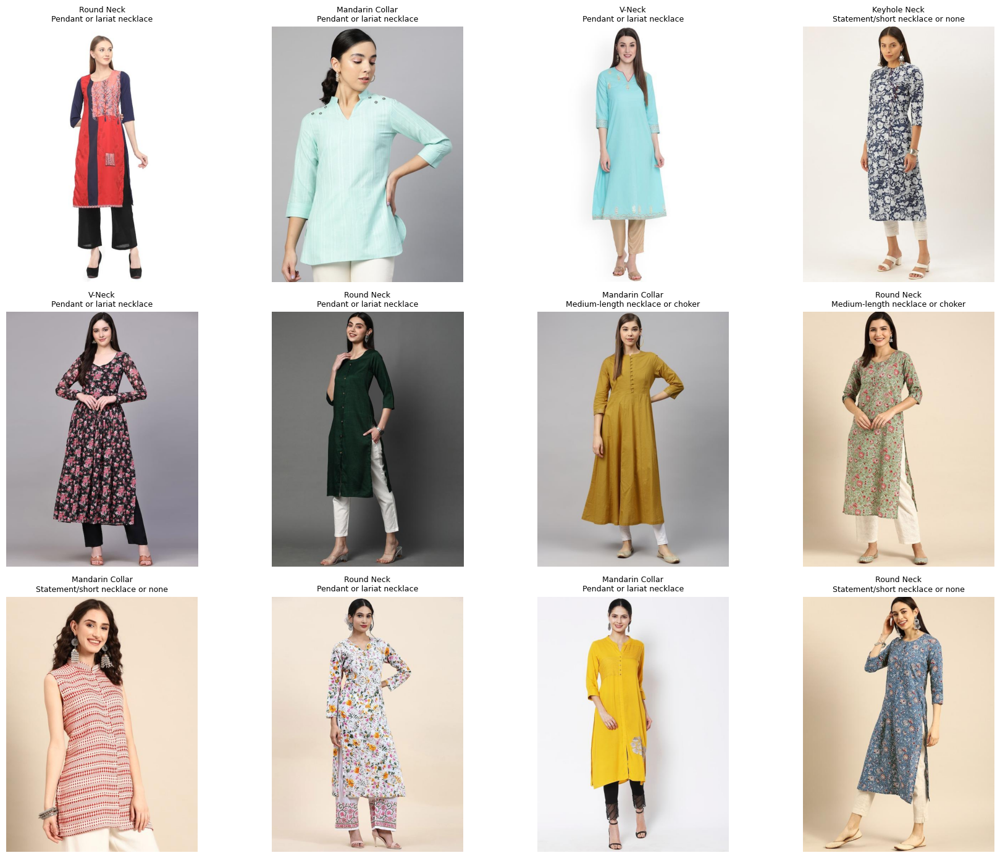

Saved


In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import random

random.seed(11)
sample = geo_df.sample(12, random_state=11)

fig, axes = plt.subplots(3, 4, figsize=(18, 14))
axes = axes.flatten()

for ax, (_, row) in zip(axes, sample.iterrows()):
    pid = row['productId']
    img_path = f'/content/kouture_local_full/{pid}.jpg'
    img = Image.open(img_path)
    ax.imshow(img)
    ax.set_title(f"{row['neckline_type']}\n{row['recommended_necklace']}", fontsize=9)
    ax.axis('off')

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/FYP_Neckline/figures/phase5_recommendations_sample.png', dpi=150)
plt.show()
print("Saved")

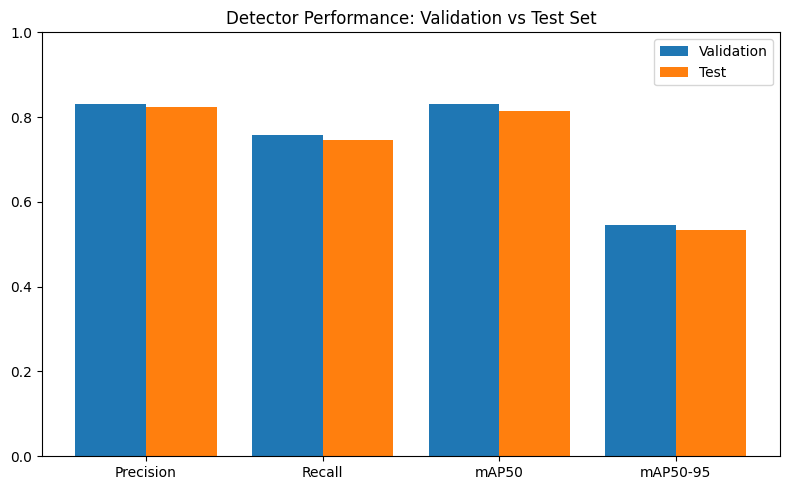

Saved: phase7_detector_performance.png


In [ ]:
import matplotlib.pyplot as plt

# Chart 1: Detector performance
metrics = ['Precision', 'Recall', 'mAP50', 'mAP50-95']
val_scores = [0.832, 0.759, 0.831, 0.545]
test_scores = [0.824, 0.747, 0.814, 0.533]

x = range(len(metrics))
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar([i - 0.2 for i in x], val_scores, width=0.4, label='Validation')
ax.bar([i + 0.2 for i in x], test_scores, width=0.4, label='Test')
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1)
ax.set_title('Detector Performance: Validation vs Test Set')
ax.legend()
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/FYP_Neckline/figures/phase7_detector_performance.png', dpi=150)
plt.show()
print("Saved: phase7_detector_performance.png")

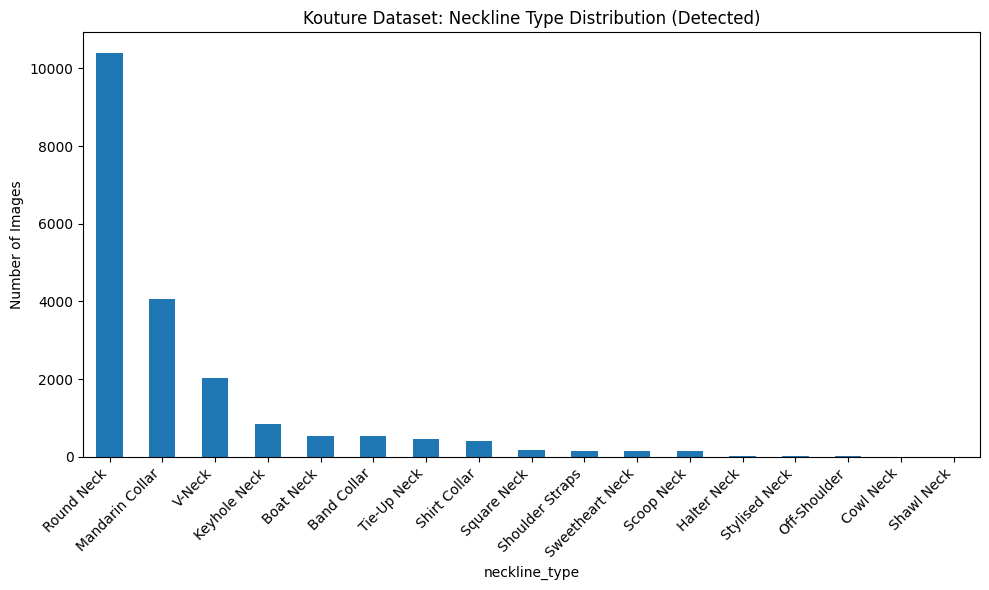

Saved: phase7_neckline_distribution.png


In [ ]:
# Chart 2: Neckline type distribution
import pandas as pd

geo_df = pd.read_csv('/content/drive/MyDrive/FYP_Neckline/results/geometry_features_full.csv')
counts = geo_df['neckline_type'].value_counts()

fig, ax = plt.subplots(figsize=(10, 6))
counts.plot(kind='bar', ax=ax)
ax.set_title('Kouture Dataset: Neckline Type Distribution (Detected)')
ax.set_ylabel('Number of Images')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/FYP_Neckline/figures/phase7_neckline_distribution.png', dpi=150)
plt.show()
print("Saved: phase7_neckline_distribution.png")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.5/46.5 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 82.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.4/78.4 kB 6.5 MB/s eta 0:00:00


In [ ]:
import shutil, os
from concurrent.futures import ThreadPoolExecutor
import time
import pandas as pd

folder = '/content/drive/MyDrive/FYP_Neckline/data/raw/kouture_images/FINAL_KURTA'
local_kouture_full = '/content/kouture_local_full'
os.makedirs(local_kouture_full, exist_ok=True)

final_df = pd.read_csv(f'{folder}/FINAL.csv')
final_df['productId'] = final_df['productId'].astype(str)
all_pids = final_df['productId'].tolist()

def copy_one(pid):
    src = f'{folder}/{pid}.jpg'
    dst = f'{local_kouture_full}/{pid}.jpg'
    if os.path.exists(src) and not os.path.exists(dst):
        shutil.copy2(src, dst)

print(f"Copying {len(all_pids)} images to local disk...")
start = time.time()
with ThreadPoolExecutor(max_workers=16) as ex:
    list(ex.map(copy_one, all_pids))

print(f"Done. {len(os.listdir(local_kouture_full))} files in {(time.time()-start)/60:.1f} min")

Copying 20000 images to local disk...
Done. 20000 files in 16.6 min


In [ ]:
import pandas as pd
from ultralytics import YOLO
import os

model = YOLO('/content/drive/MyDrive/FYP_Neckline/checkpoints/neckline_yolov8n-3/weights/best.pt')

local_kouture_full = '/content/kouture_local_full'
folder = '/content/drive/MyDrive/FYP_Neckline/data/raw/kouture_images/FINAL_KURTA'
final_df = pd.read_csv(f'{folder}/FINAL.csv')
final_df['productId'] = final_df['productId'].astype(str)

results_list = []

for i, row in final_df.iterrows():
    pid = row['productId']
    img_path = f'{local_kouture_full}/{pid}.jpg'
    if not os.path.exists(img_path):
        continue

    pred = model.predict(img_path, verbose=False)[0]
    if len(pred.boxes) == 0:
        continue

    best_idx = pred.boxes.conf.argmax().item()
    box_xywhn = pred.boxes.xywhn[best_idx].tolist()
    box_xywh_px = pred.boxes.xywh[best_idx].tolist()
    conf = pred.boxes.conf[best_idx].item()

    width_norm = box_xywhn[2]
    depth_norm = box_xywhn[3]

    box_w_px, box_h_px = box_xywh_px[2], box_xywh_px[3]
    openness_ratio = box_w_px / box_h_px if box_h_px > 0 else None

    results_list.append({
        'productId': pid,
        'neckline_type': row['Neck'],
        'width_norm': width_norm,
        'depth_norm': depth_norm,
        'openness_ratio': openness_ratio,
        'confidence': conf,
    })

    if (i + 1) % 2000 == 0:
        print(f"{i+1}/{len(final_df)} processed, {len(results_list)} with detections so far")

geo_df = pd.DataFrame(results_list)
print(f"\nTotal with detection: {len(geo_df)}")

print(f"\nBefore filtering — max openness: {geo_df['openness_ratio'].max():.2f}, min: {geo_df['openness_ratio'].min():.2f}")
q1 = geo_df['openness_ratio'].quantile(0.01)
q99 = geo_df['openness_ratio'].quantile(0.99)
geo_df_clean = geo_df[(geo_df['openness_ratio'] >= q1) & (geo_df['openness_ratio'] <= q99)].copy()
print(f"After filtering (1st-99th percentile): {len(geo_df_clean)} rows kept, {len(geo_df) - len(geo_df_clean)} outliers removed")
print(f"New max: {geo_df_clean['openness_ratio'].max():.2f}, min: {geo_df_clean['openness_ratio'].min():.2f}")

geo_df_clean.to_csv('/content/drive/MyDrive/FYP_Neckline/results/geometry_features_v2_fixed.csv', index=False)
print("\nSaved: results/geometry_features_v2_fixed.csv")

print("\nNew geometry stats by type:")
print(geo_df_clean.groupby('neckline_type')['openness_ratio'].agg(['mean', 'std', 'count']))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
2000/20000 processed, 1996 with detections so far
4000/20000 processed, 3991 with detections so far
6000/20000 processed, 5987 with detections so far
8000/20000 processed, 7977 with detections so far
10000/20000 processed, 9971 with detections so far
12000/20000 processed, 11966 with detections so far
14000/20000 processed, 13963 with detections so far
16000/20000 processed, 15952 with detections so far
18000/20000 processed, 17939 with detections so far
20000/20000 processed, 19934 with detections so far

Total with detection: 19934

Before filtering — max openness: 11.63, min: 0.61
After filtering (1st-99th percentile): 19534 rows kept, 400 outliers removed
New max: 3.00, min: 1.08

Saved: result

In [ ]:
from scipy import stats

geo_df_clean = pd.read_csv('/content/drive/MyDrive/FYP_Neckline/results/geometry_features_v2_fixed.csv')

# Restrict to types with a usable sample size (n >= 20)
type_counts = geo_df_clean['neckline_type'].value_counts()
valid_types = type_counts[type_counts >= 20].index.tolist()
print("Types included in test (n>=20):", valid_types)
print()

groups = [geo_df_clean[geo_df_clean['neckline_type'] == t]['openness_ratio'].values for t in valid_types]

h_stat, p_value = stats.kruskal(*groups)
print(f"Kruskal-Wallis H statistic: {h_stat:.2f}")
print(f"p-value: {p_value:.2e}")

# Effect size (epsilon-squared)
n_total = sum(len(g) for g in groups)
k = len(groups)
epsilon_sq = (h_stat - k + 1) / (n_total - k)
print(f"Effect size (epsilon-squared): {epsilon_sq:.4f}")
print("(0.01=small, 0.06=medium, 0.14=large — per Cohen's guidelines adapted for this test)")

Types included in test (n>=20): ['Round Neck', 'Mandarin Collar', 'V-Neck', 'Keyhole Neck', 'Band Collar', 'Boat Neck', 'Tie-Up Neck', 'Shirt Collar', 'Square Neck', 'Sweetheart Neck', 'Scoop Neck', 'Shoulder Straps', 'Halter Neck', 'Stylised Neck']

Kruskal-Wallis H statistic: 4072.58
p-value: 0.00e+00
Effect size (epsilon-squared): 0.2081
(0.01=small, 0.06=medium, 0.14=large — per Cohen's guidelines adapted for this test)


**Note:** this comparison is circular, because both sides derive from the same
variable. The full reasoning is recorded later in this notebook. The
non-circular answer comes from the human validation in the final section.

In [ ]:
# Pehle: naye (fixed) openness ratio se recommendation categories dobara banao
q30 = geo_df_clean['openness_ratio'].quantile(0.30)
q70 = geo_df_clean['openness_ratio'].quantile(0.70)
print(f"New thresholds — 30th: {q30:.3f}, 70th: {q70:.3f}\n")

def categorize(o):
    if o >= q70:
        return "Wide/shallow"
    elif o <= q30:
        return "Narrow/deep"
    else:
        return "Balanced"

geo_df_clean['geometry_category'] = geo_df_clean['openness_ratio'].apply(categorize)

# Baseline: the modal category of each type, i.e. the best guess from the label alone
type_majority = geo_df_clean.groupby('neckline_type')['geometry_category'].agg(lambda x: x.mode()[0])
geo_df_clean['type_baseline_category'] = geo_df_clean['neckline_type'].map(type_majority)

# Compare: geometry-based per-image recommendation vs type-only baseline
geo_df_clean['agrees_with_baseline'] = geo_df_clean['geometry_category'] == geo_df_clean['type_baseline_category']

overall_agreement = geo_df_clean['agrees_with_baseline'].mean()
print(f"Overall agreement (geometry vs type-only baseline): {overall_agreement:.1%}")
print(f"Disagreement (images where geometry adds new info beyond type label): {1-overall_agreement:.1%}\n")

print("Type-level majority category (the 'if you only knew the label' guess):")
print(type_majority)

print("\nDisagreement rate by type (higher = geometry adds more value for this type):")
disagreement_by_type = geo_df_clean.groupby('neckline_type')['agrees_with_baseline'].apply(lambda x: 1 - x.mean())
print(disagreement_by_type.sort_values(ascending=False))

geo_df_clean.to_csv('/content/drive/MyDrive/FYP_Neckline/results/geometry_features_v2_with_ablation.csv', index=False)
print("\nSaved: results/geometry_features_v2_with_ablation.csv")

New thresholds — 30th: 1.711, 70th: 2.050

Overall agreement (geometry vs type-only baseline): 50.5%
Disagreement (images where geometry adds new info beyond type label): 49.5%

Type-level majority category (the 'if you only knew the label' guess):
neckline_type
Band Collar         Narrow/deep
Boat Neck          Wide/shallow
Cowl Neck              Balanced
Halter Neck        Wide/shallow
Keyhole Neck           Balanced
Mandarin Collar     Narrow/deep
Off-Shoulder           Balanced
Round Neck             Balanced
Scoop Neck             Balanced
Shawl Neck          Narrow/deep
Shirt Collar        Narrow/deep
Shoulder Straps        Balanced
Square Neck         Narrow/deep
Stylised Neck          Balanced
Sweetheart Neck        Balanced
Tie-Up Neck        Wide/shallow
V-Neck              Narrow/deep
Name: geometry_category, dtype: object

Disagreement rate by type (higher = geometry adds more value for this type):
neckline_type
Square Neck        0.630303
Shoulder Straps    0.601504
Band C

In [ ]:
print("Confidence comparison — Agree vs Disagree groups:")
print(geo_df_clean.groupby('agrees_with_baseline')['confidence'].describe())

Confidence comparison — Agree vs Disagree groups:
                       count      mean       std       min       25%  \
agrees_with_baseline                                                   
False                 9668.0  0.704807  0.116700  0.250746  0.649587   
True                  9866.0  0.739837  0.095347  0.253030  0.711258   

                           50%       75%       max  
agrees_with_baseline                                
False                 0.744263  0.788726  0.894527  
True                  0.767625  0.802346  0.899696  


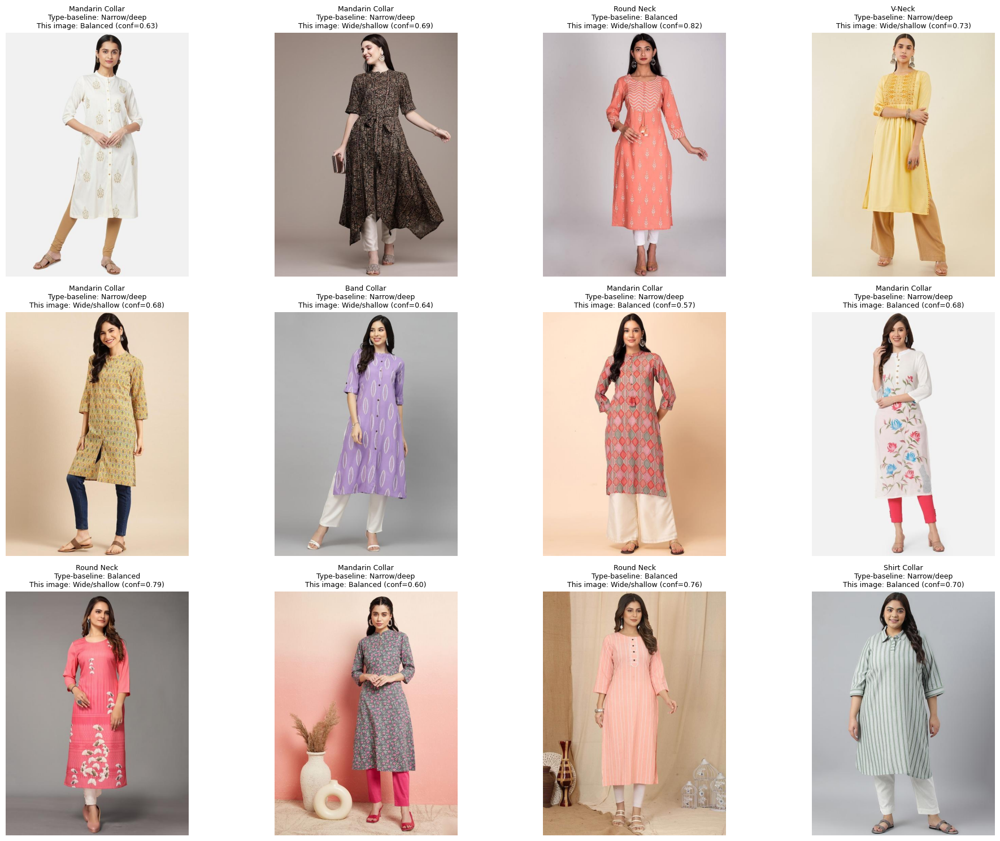

Saved


In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import random

disagree_sample = geo_df_clean[~geo_df_clean['agrees_with_baseline']].sample(12, random_state=5)

fig, axes = plt.subplots(3, 4, figsize=(20, 15))
axes = axes.flatten()

for ax, (_, row) in zip(axes, disagree_sample.iterrows()):
    pid = row['productId']
    img_path = f'/content/kouture_local_full/{pid}.jpg'
    img = Image.open(img_path)
    ax.imshow(img)
    title = (f"{row['neckline_type']}\n"
              f"Type-baseline: {row['type_baseline_category']}\n"
              f"This image: {row['geometry_category']} (conf={row['confidence']:.2f})")
    ax.set_title(title, fontsize=9)
    ax.axis('off')

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/FYP_Neckline/figures/ablation_disagreement_spotcheck.png', dpi=150)
plt.show()
print("Saved")

Suspect cases: 2307 out of 4450


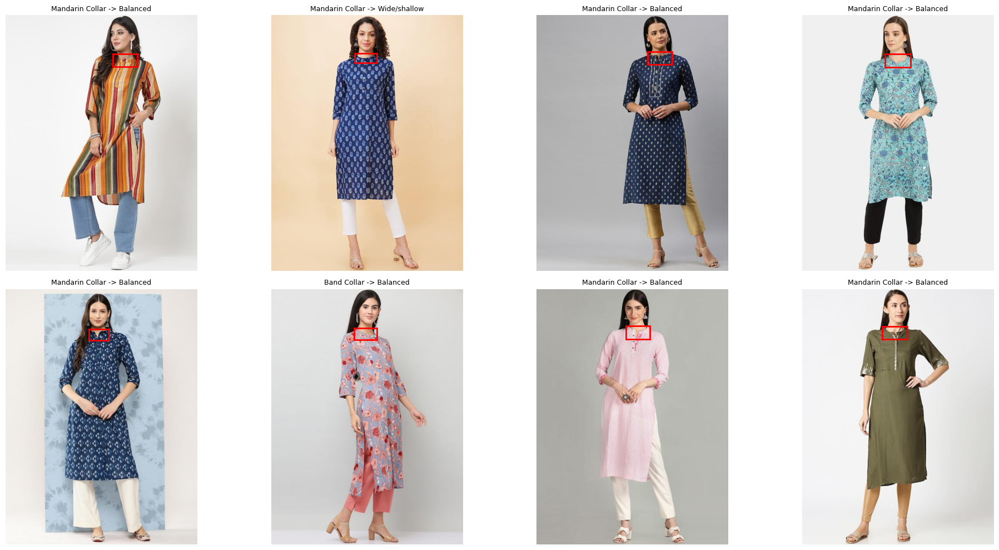

Saved


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import random

suspect = geo_df_clean[
    (geo_df_clean['neckline_type'].isin(['Mandarin Collar', 'Band Collar'])) &
    (geo_df_clean['geometry_category'] != 'Narrow/deep')
]
print(f"Suspect cases: {len(suspect)} out of {len(geo_df_clean[geo_df_clean['neckline_type'].isin(['Mandarin Collar','Band Collar'])])}")

sample = suspect.sample(min(8, len(suspect)), random_state=3)

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for ax, (_, row) in zip(axes, sample.iterrows()):
    pid = row['productId']
    img_path = f'/content/kouture_local_full/{pid}.jpg'
    img = Image.open(img_path)
    img_w, img_h = img.size

    pred = model.predict(img_path, verbose=False)[0]
    if len(pred.boxes) > 0:
        best_idx = pred.boxes.conf.argmax().item()
        box_px = pred.boxes.xyxy[best_idx].tolist()
        ax.imshow(img)
        rect = patches.Rectangle((box_px[0], box_px[1]), box_px[2]-box_px[0], box_px[3]-box_px[1],
                                   linewidth=2, edgecolor='red', facecolor='none')
        ax.add_patch(rect)
    ax.set_title(f"{row['neckline_type']} -> {row['geometry_category']}", fontsize=9)
    ax.axis('off')

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/FYP_Neckline/figures/mandarin_wide_boxcheck.png', dpi=150)
plt.show()
print("Saved")

In [ ]:
print("Recommendation distribution (using FIXED openness ratio + quantile thresholds):")
print(geo_df_clean['geometry_category'].value_counts())

print("\nPer-type crosstab (fixed):")
crosstab_fixed = pd.crosstab(geo_df_clean['neckline_type'], geo_df_clean['geometry_category'])
print(crosstab_fixed)

# Percentage consistency checks
round_total = crosstab_fixed.loc['Round Neck'].sum()
round_wide_pct = 100 * crosstab_fixed.loc['Round Neck', 'Wide/shallow'] / round_total
print(f"\nRound Neck wide/shallow %: {round_wide_pct:.1f}%")

vneck_total = crosstab_fixed.loc['V-Neck'].sum()
vneck_narrow_pct = 100 * crosstab_fixed.loc['V-Neck', 'Narrow/deep'] / vneck_total
print(f"V-Neck narrow/deep %: {vneck_narrow_pct:.1f}%")

boat_total = crosstab_fixed.loc['Boat Neck'].sum()
boat_wide_pct = 100 * crosstab_fixed.loc['Boat Neck', 'Wide/shallow'] / boat_total
print(f"Boat Neck wide/shallow %: {boat_wide_pct:.1f}%")

Recommendation distribution (using FIXED openness ratio + quantile thresholds):
geometry_category
Balanced        7814
Wide/shallow    5860
Narrow/deep     5860
Name: count, dtype: int64

Per-type crosstab (fixed):
geometry_category  Balanced  Narrow/deep  Wide/shallow
neckline_type                                         
Band Collar             173          211           131
Boat Neck               116           16           365
Cowl Neck                 2            1             0
Halter Neck               5            1            20
Keyhole Neck            362          117           351
Mandarin Collar        1201         1932           802
Off-Shoulder              5            2             1
Round Neck             4860         1715          3724
Scoop Neck               69           47            21
Shawl Neck                0            2             0
Shirt Collar            118          247            23
Shoulder Straps          53           29            51
Square Neck    

**Superseded** - these numbers predate the box-area filter
(us waqt filter khud openness_ratio pe tha — circular). Final, sahi
numbers neeche wali "Closed collar" override wali cell mein hain:
Balanced 6,331 / Wide-shallow 4,948 / Closed collar 4,830 /
Narrow-deep 3,425.

In [ ]:
from datasets import load_dataset

ds_train = load_dataset("detection-datasets/fashionpedia", split="train")
ds_val = load_dataset("detection-datasets/fashionpedia", split="val")
print("Fashionpedia reloaded.")

README.md:   0%|          | 0.00/5.22k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/1.78k [00:00<?, ?B/s]

data/train-00000-of-00007-fe108070118553(…): reconstructing file:   0%|          |  0.00B /  482MB            

data/train-00000-of-00007-fe108070118553(…): downloading bytes:           |  0.00B            

data/train-00001-of-00007-f41a5a9c38c900(…): reconstructing file:   0%|          |  0.00B /  480MB            

...

data/val-00000-of-00001-0b29e85429788213(…): reconstructing file:   0%|          |  0.00B / 84.8MB            

data/val-00000-of-00001-0b29e85429788213(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/45623 [00:00<?, ? examples/s]

Generating val split:   0%|          | 0/1158 [00:00<?, ? examples/s]

Fashionpedia reloaded.


In [ ]:
import json, os
from PIL import Image

local_base = '/content/yolo_dataset_local'
for split in ['train', 'val', 'test']:
    os.makedirs(f'{local_base}/images/{split}', exist_ok=True)
    os.makedirs(f'{local_base}/labels/{split}', exist_ok=True)

for split_name in ['train', 'val', 'test']:
    with open(f'/content/drive/MyDrive/FYP_Neckline/data/splits/{split_name}_manifest.json') as f:
        manifest = json.load(f)
    print(f"Converting {split_name}: {len(manifest)} images...")
    for i, item in enumerate(manifest):
        ds = ds_train if item['hf_split'] == 'train' else ds_val
        ex = ds[item['hf_index']]
        img = ex['image']
        img_w, img_h = item['width'], item['height']
        x, y, w, h = item['neckline_bbox_xywh']
        cx = (x + w / 2) / img_w
        cy = (y + h / 2) / img_h
        nw = w / img_w
        nh = h / img_h
        img.convert('RGB').save(f'{local_base}/images/{split_name}/fp_{item["image_id"]}.jpg')
        with open(f'{local_base}/labels/{split_name}/fp_{item["image_id"]}.txt', 'w') as lf:
            lf.write(f"0 {cx:.6f} {cy:.6f} {nw:.6f} {nh:.6f}\n")
        if (i + 1) % 5000 == 0:
            print(f"  {i+1}/{len(manifest)} done")
    print(f"{split_name} complete.\n")
print("Fashionpedia -> local YOLO conversion done.")

Converting train: 27244 images...
  5000/27244 done
  10000/27244 done
  15000/27244 done
  20000/27244 done
  25000/27244 done
train complete.

Converting val: 3405 images...
val complete.

Converting test: 3406 images...
test complete.

Fashionpedia -> local YOLO conversion done.


In [ ]:
import pandas as pd
import random

folder = '/content/drive/MyDrive/FYP_Neckline/data/raw/kouture_images/FINAL_KURTA'
ann_df = pd.read_csv(f'{folder}/_annotations.csv')
neck_boxes = ann_df[ann_df['class'] == 'Neck'].copy()
neck_boxes['productId'] = neck_boxes['filename'].str.split('_jpg.rf.').str[0]

random.seed(42)
pids = neck_boxes['productId'].unique().tolist()
random.shuffle(pids)
n = len(pids)
train_end = int(n * 0.8)
val_end = int(n * 0.9)
split_map = {}
for pid in pids[:train_end]: split_map[pid] = 'train'
for pid in pids[train_end:val_end]: split_map[pid] = 'val'
for pid in pids[val_end:]: split_map[pid] = 'test'

for _, row in neck_boxes.iterrows():
    pid = row['productId']
    split_name = split_map[pid]
    img = Image.open(f'/content/kouture_local_full/{pid}.jpg').convert('RGB')
    img_w, img_h = img.size
    x, y = row['xmin'], row['ymin']
    w, h = row['xmax'] - row['xmin'], row['ymax'] - row['ymin']
    cx, cy = (x + w/2)/img_w, (y + h/2)/img_h
    nw, nh = w/img_w, h/img_h
    img.save(f'/content/yolo_dataset_local/images/{split_name}/kt_{pid}.jpg')
    with open(f'/content/yolo_dataset_local/labels/{split_name}/kt_{pid}.txt', 'w') as lf:
        lf.write(f"0 {cx:.6f} {cy:.6f} {nw:.6f} {nh:.6f}\n")
print("Kouture -> local YOLO conversion done.")

Kouture -> local YOLO conversion done.


In [ ]:
import os
import shutil

test_img_dir = '/content/yolo_dataset_local/images/test'
test_lbl_dir = '/content/yolo_dataset_local/labels/test'

for source in ['fashionpedia', 'kouture']:
    os.makedirs(f'/content/yolo_dataset_local/images/test_{source}', exist_ok=True)
    os.makedirs(f'/content/yolo_dataset_local/labels/test_{source}', exist_ok=True)

fp_count, kt_count = 0, 0
for fname in os.listdir(test_img_dir):
    if fname.startswith('fp_'):
        shutil.copy2(f'{test_img_dir}/{fname}', f'/content/yolo_dataset_local/images/test_fashionpedia/{fname}')
        lbl_name = fname.replace('.jpg', '.txt')
        shutil.copy2(f'{test_lbl_dir}/{lbl_name}', f'/content/yolo_dataset_local/labels/test_fashionpedia/{lbl_name}')
        fp_count += 1
    elif fname.startswith('kt_'):
        shutil.copy2(f'{test_img_dir}/{fname}', f'/content/yolo_dataset_local/images/test_kouture/{fname}')
        lbl_name = fname.replace('.jpg', '.txt')
        shutil.copy2(f'{test_lbl_dir}/{lbl_name}', f'/content/yolo_dataset_local/labels/test_kouture/{lbl_name}')
        kt_count += 1

print(f"Fashionpedia test images: {fp_count}")
print(f"Kouture test images: {kt_count}")

for source in ['fashionpedia', 'kouture']:
    yaml_content = f"""
path: /content/yolo_dataset_local
train: images/train
val: images/test_{source}
test: images/test_{source}

names:
  0: neckline
"""
    with open(f'/content/yolo_dataset_local/neckline_{source}.yaml', 'w') as f:
        f.write(yaml_content)

print("YAML files created for both sources")

Fashionpedia test images: 3406
Kouture test images: 200
YAML files created for both sources


In [ ]:
from ultralytics import YOLO

model = YOLO('/content/drive/MyDrive/FYP_Neckline/checkpoints/neckline_yolov8n-3/weights/best.pt')

print("=" * 50)
print("FASHIONPEDIA TEST SET")
print("=" * 50)
fp_results = model.val(data='/content/yolo_dataset_local/neckline_fashionpedia.yaml', split='test')

print("\n" + "=" * 50)
print("KOUTURE TEST SET")
print("=" * 50)
kt_results = model.val(data='/content/yolo_dataset_local/neckline_kouture.yaml', split='test')

print("\n\nSUMMARY:")
print(f"Fashionpedia (n=3406) - mAP50: {fp_results.box.map50:.3f}, mAP50-95: {fp_results.box.map:.3f}, Precision: {fp_results.box.p[0]:.3f}, Recall: {fp_results.box.r[0]:.3f}")
print(f"Kouture (n=200)       - mAP50: {kt_results.box.map50:.3f}, mAP50-95: {kt_results.box.map:.3f}, Precision: {kt_results.box.p[0]:.3f}, Recall: {kt_results.box.r[0]:.3f}")

FASHIONPEDIA TEST SET
Ultralytics 8.4.155 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1083.4±401.9 MB/s, size: 66.9 KB)
val: Scanning /content/yolo_dataset_local/labels/test_fashionpedia... 3406 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3406/3406 608.2it/s 5.6s
val: New cache created: /content/yolo_dataset_local/labels/test_fashionpedia.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 213/213 6.0it/s 35.7s
                   all       3406       3406      0.814      0.733        0.8      0.525
Speed: 1.2ms preprocess, 3.1ms inference, 0.0ms loss, 1.4ms postprocess per image
Results saved to /content/runs/detect/val

KOUTURE TEST SET
Ultralytics 8.4.155 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,005,843 parame

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install -q ultralytics imagehash

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.5/46.5 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 68.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 26.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.4/78.4 kB 8.6 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO
model = YOLO('/content/drive/MyDrive/FYP_Neckline/checkpoints/neckline_yolov8n-3/weights/best.pt')
print("Model loaded")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Model loaded


In [ ]:
import pandas as pd
results_path = '/content/drive/MyDrive/FYP_Neckline/checkpoints/neckline_yolov8n-3/results.csv'
results_df = pd.read_csv(results_path)
print("Total epoch rows in results.csv:", len(results_df))
print("Last epoch number:", results_df['epoch'].iloc[-1])

Total epoch rows in results.csv: 30
Last epoch number: 30


In [ ]:
import shutil, os
from concurrent.futures import ThreadPoolExecutor
import time
import pandas as pd

folder = '/content/drive/MyDrive/FYP_Neckline/data/raw/kouture_images/FINAL_KURTA'
local_kouture_full = '/content/kouture_local_full'
os.makedirs(local_kouture_full, exist_ok=True)

final_df = pd.read_csv(f'{folder}/FINAL.csv')
final_df['productId'] = final_df['productId'].astype(str)
all_pids = final_df['productId'].tolist()

def copy_one(pid):
    src = f'{folder}/{pid}.jpg'
    dst = f'{local_kouture_full}/{pid}.jpg'
    if os.path.exists(src) and not os.path.exists(dst):
        shutil.copy2(src, dst)

print(f"Copying {len(all_pids)} images...")
start = time.time()
with ThreadPoolExecutor(max_workers=16) as ex:
    list(ex.map(copy_one, all_pids))
print(f"Done. {len(os.listdir(local_kouture_full))} files in {(time.time()-start)/60:.1f} min")

Copying 20000 images...
Done. 20000 files in 17.1 min


In [ ]:
import pandas as pd
import os

local_kouture_full = '/content/kouture_local_full'
folder = '/content/drive/MyDrive/FYP_Neckline/data/raw/kouture_images/FINAL_KURTA'
final_df = pd.read_csv(f'{folder}/FINAL.csv')
final_df['productId'] = final_df['productId'].astype(str)

results_list = []

for i, row in final_df.iterrows():
    pid = row['productId']
    img_path = f'{local_kouture_full}/{pid}.jpg'
    if not os.path.exists(img_path):
        continue

    pred = model.predict(img_path, verbose=False)[0]
    if len(pred.boxes) == 0:
        continue

    best_idx = pred.boxes.conf.argmax().item()
    box_xywhn = pred.boxes.xywhn[best_idx].tolist()   # normalized [cx,cy,w,h]
    box_xywh_px = pred.boxes.xywh[best_idx].tolist()   # PIXEL [cx,cy,w,h]
    conf = pred.boxes.conf[best_idx].item()

    img_w_full = pred.orig_shape[1]
    img_h_full = pred.orig_shape[0]

    box_w_px, box_h_px = box_xywh_px[2], box_xywh_px[3]
    box_area_frac = (box_w_px * box_h_px) / (img_w_full * img_h_full)  # box kitna % image ka hai

    openness_ratio = box_w_px / box_h_px if box_h_px > 0 else None

    results_list.append({
        'productId': pid,
        'neckline_type': row['Neck'],
        'box_w_px': box_w_px,
        'box_h_px': box_h_px,
        'box_area_frac': box_area_frac,
        'openness_ratio': openness_ratio,
        'confidence': conf,
    })

    if (i + 1) % 2000 == 0:
        print(f"{i+1}/{len(final_df)} processed, {len(results_list)} with detections so far")

geo_df_raw = pd.DataFrame(results_list)
print(f"\nTotal with detection: {len(geo_df_raw)}")

geo_df_raw.to_csv('/content/drive/MyDrive/FYP_Neckline/results/geometry_features_v3_raw.csv', index=False)
print("Saved: results/geometry_features_v3_raw.csv")

# Diagnostic: distribution of box_area_frac and confidence, used to set filter thresholds
print("\nbox_area_frac stats:")
print(geo_df_raw['box_area_frac'].describe())
print("\nconfidence stats:")
print(geo_df_raw['confidence'].describe())

2000/20000 processed, 1996 with detections so far
4000/20000 processed, 3991 with detections so far
6000/20000 processed, 5987 with detections so far
8000/20000 processed, 7977 with detections so far
10000/20000 processed, 9971 with detections so far
12000/20000 processed, 11966 with detections so far
14000/20000 processed, 13963 with detections so far
16000/20000 processed, 15952 with detections so far
18000/20000 processed, 17939 with detections so far
20000/20000 processed, 19934 with detections so far

Total with detection: 19934
Saved: results/geometry_features_v3_raw.csv

box_area_frac stats:
count    19934.000000
mean         0.008731
std          0.003837
min          0.000378
25%          0.006491
50%          0.008214
75%          0.009975
max          0.055039
Name: box_area_frac, dtype: float64

confidence stats:
count    19934.000000
mean         0.720339
std          0.109803
min          0.250746
25%          0.679386
50%          0.755869
75%          0.795353
max      

In [ ]:
import pandas as pd

geo_df_raw = pd.read_csv('/content/drive/MyDrive/FYP_Neckline/results/geometry_features_v3_raw.csv')

# Filter on box_area_frac percentiles only. The openness ratio is never filtered on itself
area_q1 = geo_df_raw['box_area_frac'].quantile(0.01)
area_q99 = geo_df_raw['box_area_frac'].quantile(0.99)
print(f"Area fraction filter range: {area_q1:.5f} to {area_q99:.5f}")

geo_df_clean = geo_df_raw[
    (geo_df_raw['box_area_frac'] >= area_q1) &
    (geo_df_raw['box_area_frac'] <= area_q99)
].copy()

print(f"Kept: {len(geo_df_clean)} / {len(geo_df_raw)} ({100*len(geo_df_clean)/len(geo_df_raw):.1f}%)")
print(f"Removed: {len(geo_df_raw) - len(geo_df_clean)} images")

geo_df_clean.to_csv('/content/drive/MyDrive/FYP_Neckline/results/geometry_features_v3_clean.csv', index=False)
print("Saved: results/geometry_features_v3_clean.csv")

print("\nGeometry stats by type (area-filtered, NOT openness-filtered):")
stats = geo_df_clean.groupby('neckline_type')['openness_ratio'].agg(['mean', 'std', 'count']).sort_values('mean', ascending=False)
print(stats)

print(f"\nOpenness ratio range now: {geo_df_clean['openness_ratio'].min():.2f} to {geo_df_clean['openness_ratio'].max():.2f}")

Area fraction filter range: 0.00324 to 0.02537
Kept: 19534 / 19934 (98.0%)
Removed: 400 images
Saved: results/geometry_features_v3_clean.csv

Geometry stats by type (area-filtered, NOT openness-filtered):
                     mean       std  count
neckline_type                             
Off-Shoulder     4.070665  3.335600     13
Boat Neck        2.336863  0.654398    517
Halter Neck      2.255969  0.346671     26
Shoulder Straps  2.159961  0.765104    146
Tie-Up Neck      2.082471  0.356869    451
Keyhole Neck     2.010477  0.313725    835
Round Neck       1.978391  0.310483  10262
Square Neck      1.870671  0.401222    161
Stylised Neck    1.849135  0.368556     24
Sweetheart Neck  1.826721  0.237261    144
Scoop Neck       1.813181  0.274691    137
Cowl Neck        1.794666  0.296708      3
Band Collar      1.777134  0.362118    517
Mandarin Collar  1.706903  0.384558   3921
Shirt Collar     1.594325  0.283579    392
V-Neck           1.575205  0.265431   1981
Shawl Neck       1.28

In [ ]:
import imagehash
from PIL import Image
import random
import pandas as pd

folder = '/content/drive/MyDrive/FYP_Neckline/data/raw/kouture_images/FINAL_KURTA'
local_kouture_full = '/content/kouture_local_full'

ann_df = pd.read_csv(f'{folder}/_annotations.csv')
neck_boxes = ann_df[ann_df['class'] == 'Neck'].copy()
neck_boxes['productId'] = neck_boxes['filename'].str.split('_jpg.rf.').str[0]

# Rebuild the exact detector train/test split (seed 42)
random.seed(42)
pids = neck_boxes['productId'].unique().tolist()
random.shuffle(pids)
n = len(pids)
train_end = int(n * 0.8)
val_end = int(n * 0.9)

train_pids = pids[:train_end]
test_pids = pids[val_end:]

print(f"Train: {len(train_pids)}, Test: {len(test_pids)}")

# Compute a perceptual hash for every image
def get_hash(pid):
    try:
        img = Image.open(f'{local_kouture_full}/{pid}.jpg')
        return imagehash.phash(img)
    except:
        return None

train_hashes = {pid: get_hash(pid) for pid in train_pids}
test_hashes = {pid: get_hash(pid) for pid in test_pids}

# Compare every test image against every train image (hash distance <= 5 counts as a near-duplicate)
duplicates = []
for test_pid, test_hash in test_hashes.items():
    if test_hash is None:
        continue
    for train_pid, train_hash in train_hashes.items():
        if train_hash is None:
            continue
        distance = test_hash - train_hash
        if distance <= 5:  # threshold: near-identical images
            duplicates.append({'test_pid': test_pid, 'train_pid': train_pid, 'hash_distance': distance})

dup_df = pd.DataFrame(duplicates)
print(f"\nNear-duplicate pairs found (test image matching a train image): {len(dup_df)}")
if len(dup_df) > 0:
    print(dup_df.sort_values('hash_distance').head(20))
    unique_test_affected = dup_df['test_pid'].nunique()
    print(f"\nUnique test images affected: {unique_test_affected} / {len(test_pids)} ({100*unique_test_affected/len(test_pids):.1f}%)")

dup_df.to_csv('/content/drive/MyDrive/FYP_Neckline/results/duplicate_check.csv', index=False)
print("Saved: results/duplicate_check.csv")

Train: 1596, Test: 200

Near-duplicate pairs found (test image matching a train image): 0
Saved: results/duplicate_check.csv


In [ ]:
geo_df_clean = pd.read_csv('/content/drive/MyDrive/FYP_Neckline/results/geometry_features_v3_clean.csv')

# Recompute quantile thresholds on the area-filtered data
q30 = geo_df_clean['openness_ratio'].quantile(0.30)
q70 = geo_df_clean['openness_ratio'].quantile(0.70)
print(f"Thresholds — 30th: {q30:.3f}, 70th: {q70:.3f}")

CLOSED_COLLAR_TYPES = ['Mandarin Collar', 'Band Collar', 'Shirt Collar']

def recommend(row):
    if row['neckline_type'] in CLOSED_COLLAR_TYPES:
        # Type-label override: closed collar, geometry openness is not meaningful here
        return "Closed collar", "Statement necklace worn open/layered, or brooch — no pendant (no open space)", "Long drop earrings or jhumkas"
    elif row['openness_ratio'] >= q70:
        return "Wide/shallow", "Statement or no necklace", "Long jhumkas or chandelier earrings"
    elif row['openness_ratio'] <= q30:
        return "Narrow/deep", "Pendant or lariat necklace", "Studs or small drops"
    else:
        return "Balanced", "Medium-length necklace or choker", "Medium drop earrings or jhumkas"

geo_df_clean[['category', 'recommended_necklace', 'recommended_earrings']] = geo_df_clean.apply(
    lambda row: pd.Series(recommend(row)), axis=1
)

print("\nNew category distribution:")
print(geo_df_clean['category'].value_counts())

print(f"\nImages routed via type-label override (closed collar): {geo_df_clean['neckline_type'].isin(CLOSED_COLLAR_TYPES).sum()} ({100*geo_df_clean['neckline_type'].isin(CLOSED_COLLAR_TYPES).sum()/len(geo_df_clean):.1f}%)")

geo_df_clean.to_csv('/content/drive/MyDrive/FYP_Neckline/results/recommendations_v3_final.csv', index=False)
print("Saved: results/recommendations_v3_final.csv")

Thresholds — 30th: 1.708, 70th: 2.052

New category distribution:
category
Balanced         6331
Wide/shallow     4948
Closed collar    4830
Narrow/deep      3425
Name: count, dtype: int64

Images routed via type-label override (closed collar): 4830 (24.7%)
Saved: results/recommendations_v3_final.csv


In [ ]:
from scipy import stats

# Exclude closed-collar types, where the openness ratio is not meaningful
open_neckline_df = geo_df_clean[~geo_df_clean['neckline_type'].isin(CLOSED_COLLAR_TYPES)]

type_counts = open_neckline_df['neckline_type'].value_counts()
valid_types = type_counts[type_counts >= 20].index.tolist()
print("Types in test (open necklines only, n>=20):", valid_types)

groups = [open_neckline_df[open_neckline_df['neckline_type'] == t]['openness_ratio'].values for t in valid_types]
h_stat, p_value = stats.kruskal(*groups)

n_total = sum(len(g) for g in groups)
k = len(groups)
epsilon_sq = (h_stat - k + 1) / (n_total - k)

print(f"\nH statistic: {h_stat:.2f}")
print(f"p-value: {p_value:.2e}")
print(f"Epsilon-squared: {epsilon_sq:.4f}")
print(f"Interpretation: neckline type explains ~{epsilon_sq*100:.1f}% of rank variance in openness_ratio; ~{(1-epsilon_sq)*100:.1f}% remains unexplained")

Types in test (open necklines only, n>=20): ['Round Neck', 'V-Neck', 'Keyhole Neck', 'Boat Neck', 'Tie-Up Neck', 'Square Neck', 'Shoulder Straps', 'Sweetheart Neck', 'Scoop Neck', 'Halter Neck', 'Stylised Neck']

H statistic: 3117.01
p-value: 0.00e+00
Epsilon-squared: 0.2118
Interpretation: neckline type explains ~21.2% of rank variance in openness_ratio; ~78.8% remains unexplained


### Note on the Class-Only Comparison

The original comparison (per-image geometry category vs. each type's own modal
geometry category) is circular: both sides are derived from the same variable
(openness_ratio), so the 49.5% disagreement measures within-class variance of
that one feature, not whether geometry outperforms the type label at the actual
recommendation task. This does not answer the intended question and should not
be presented as evidence that geometry "adds value" beyond the type label.

The confidence check (agree=0.740 vs disagree=0.705, overlapping ranges) remains
valid as a separate, non-circular finding: it rules out low detection confidence
as the driver of within-class disagreement.

The actual question — does geometry improve recommendations relative to type-label-only —
is blocked on external ground truth and will be answered by the human validation
study (Section below / see human_eval results), not by this ablation.

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import os
import random

geo_df_final = pd.read_csv('/content/drive/MyDrive/FYP_Neckline/results/recommendations_v3_final.csv')

# Stratified sample: 30 images per category (4 categories x 30 = 120)
random.seed(99)
samples = []
for cat in geo_df_final['category'].unique():
    subset = geo_df_final[geo_df_final['category'] == cat]
    n_sample = min(30, len(subset))
    samples.append(subset.sample(n_sample, random_state=99))

eval_sample = pd.concat(samples).reset_index(drop=True)
print(f"Total sample for human evaluation: {len(eval_sample)}")
print(eval_sample['category'].value_counts())

# Folder banao jaha labeled images save hongi
eval_dir = '/content/drive/MyDrive/FYP_Neckline/human_eval'
os.makedirs(eval_dir, exist_ok=True)

for i, row in eval_sample.iterrows():
    pid = row['productId']
    img_path = f'/content/kouture_local_full/{pid}.jpg'
    img = Image.open(img_path)

    fig, ax = plt.subplots(figsize=(5, 7))
    ax.imshow(img)
    ax.axis('off')
    caption = f"Image ID: {i+1:03d}\nNeckline: {row['neckline_type']}\nRecommended: {row['recommended_necklace']}"
    ax.set_title(caption, fontsize=10, wrap=True)
    plt.tight_layout()
    plt.savefig(f'{eval_dir}/eval_{i+1:03d}.png', dpi=120)
    plt.close()

    if (i+1) % 30 == 0:
        print(f"{i+1}/120 saved")

print("All 120 labeled images saved to human_eval/")

# Rating sheet (CSV) banao — raters yahan Yes/No bharenge
eval_sample_out = eval_sample.reset_index(drop=True)
eval_sample_out.insert(0, 'image_id', [f"{i+1:03d}" for i in range(len(eval_sample_out))])
rating_sheet = eval_sample_out[['image_id', 'productId', 'neckline_type', 'category', 'recommended_necklace', 'recommended_earrings']].copy()
rating_sheet['rater1_appropriate(Y/N)'] = ''
rating_sheet['rater2_appropriate(Y/N)'] = ''
rating_sheet['rater3_appropriate(Y/N)'] = ''

rating_sheet.to_csv(f'{eval_dir}/rating_sheet.csv', index=False)
print(f"\nSaved rating sheet: {eval_dir}/rating_sheet.csv")

Total sample for human evaluation: 120
category
Closed collar    30
Wide/shallow     30
Balanced         30
Narrow/deep      30
Name: count, dtype: int64
30/120 saved
60/120 saved
90/120 saved
120/120 saved
All 120 labeled images saved to human_eval/

Saved rating sheet: /content/drive/MyDrive/FYP_Neckline/human_eval/rating_sheet.csv


In [ ]:
import pandas as pd

ratings = pd.read_csv('/content/drive/MyDrive/FYP_Neckline/human_eval/rating_sheet_done.csv')
print("Columns:", list(ratings.columns))
print("Shape:", ratings.shape)
print("\nFirst few rows:")
print(ratings.head(10))

print("\nMissing values check:")
print(ratings[['rater1_appropriate(Y/N)', 'rater2_appropriate(Y/N)', 'rater3_appropriate(Y/N)']].isna().sum())

Columns: ['image_id', 'productId', 'neckline_type', 'category', 'recommended_necklace', 'recommended_earrings', 'rater1_appropriate(Y/N)', 'rater2_appropriate(Y/N)', 'rater3_appropriate(Y/N)']
Shape: (120, 9)

First few rows:
   image_id  productId    neckline_type       category  \
0         1   18712918  Mandarin Collar  Closed collar   
1         2   17430402  Mandarin Collar  Closed collar   
2         3   17425244      Band Collar  Closed collar   
3         4   24474180     Shirt Collar  Closed collar   
4         5   21748278  Mandarin Collar  Closed collar   
5         6   22023856  Mandarin Collar  Closed collar   
6         7   21724002      Band Collar  Closed collar   
7         8   27129308  Mandarin Collar  Closed collar   
8         9   26512018  Mandarin Collar  Closed collar   
9        10   14370146  Mandarin Collar  Closed collar   

                                recommended_necklace  \
0  Statement necklace worn open/layered, or brooc...   
1  Statement necklace w

In [ ]:
import pandas as pd
import numpy as np

ratings = pd.read_csv('/content/drive/MyDrive/FYP_Neckline/human_eval/rating_sheet_done.csv')

r_cols = ['rater1_appropriate(Y/N)', 'rater2_appropriate(Y/N)', 'rater3_appropriate(Y/N)']

# 1. Per-rater accuracy (kitne % ko "Y" bola)
print("=== Per-rater Y percentage ===")
for col in r_cols:
    y_pct = (ratings[col] == 'Y').mean() * 100
    print(f"{col}: {y_pct:.1f}% Y")

# 2. Majority vote per image (2/3 raters agree karein to wahi final label)
def majority_vote(row):
    votes = [row[c] for c in r_cols]
    y_count = votes.count('Y')
    return 'Y' if y_count >= 2 else 'N'

ratings['majority'] = ratings.apply(majority_vote, axis=1)
overall_majority_y = (ratings['majority'] == 'Y').mean() * 100
print(f"\n=== Overall majority-vote appropriateness: {overall_majority_y:.1f}% ===")

# 3. Per-category breakdown (majority vote)
print("\n=== Per-category appropriateness (majority vote) ===")
cat_breakdown = ratings.groupby('category')['majority'].apply(lambda x: (x=='Y').mean()*100)
print(cat_breakdown)

# 4. Inter-rater agreement — Fleiss' Kappa
from statsmodels.stats.inter_rater import fleiss_kappa, aggregate_raters

rating_matrix = ratings[r_cols].values
agg, _ = aggregate_raters(rating_matrix)
kappa = fleiss_kappa(agg)
print(f"\n=== Fleiss' Kappa (inter-rater agreement): {kappa:.3f} ===")
print("(< 0: poor, 0-0.2: slight, 0.2-0.4: fair, 0.4-0.6: moderate, 0.6-0.8: substantial, 0.8-1: almost perfect)")

# 5. Simple pairwise % agreement (easier to explain in the paper)
def pairwise_agreement(c1, c2):
    return (ratings[c1] == ratings[c2]).mean() * 100

print(f"\n=== Pairwise agreement % ===")
print(f"Rater1 vs Rater2: {pairwise_agreement(r_cols[0], r_cols[1]):.1f}%")
print(f"Rater1 vs Rater3: {pairwise_agreement(r_cols[0], r_cols[2]):.1f}%")
print(f"Rater2 vs Rater3: {pairwise_agreement(r_cols[1], r_cols[2]):.1f}%")

# Save final results
ratings.to_csv('/content/drive/MyDrive/FYP_Neckline/results/human_eval_final.csv', index=False)
print("\nSaved: results/human_eval_final.csv")

=== Per-rater Y percentage ===
rater1_appropriate(Y/N): 96.7% Y
rater2_appropriate(Y/N): 97.5% Y
rater3_appropriate(Y/N): 95.8% Y

=== Overall majority-vote appropriateness: 97.5% ===

=== Per-category appropriateness (majority vote) ===
category
Balanced          96.666667
Closed collar     93.333333
Narrow/deep      100.000000
Wide/shallow     100.000000
Name: majority, dtype: float64

=== Fleiss' Kappa (inter-rater agreement): 0.224 ===
(< 0: poor, 0-0.2: slight, 0.2-0.4: fair, 0.4-0.6: moderate, 0.6-0.8: substantial, 0.8-1: almost perfect)

=== Pairwise agreement % ===
Rater1 vs Rater2: 94.2%
Rater1 vs Rater3: 94.2%
Rater2 vs Rater3: 96.7%

Saved: results/human_eval_final.csv


In [ ]:
# Images where at least one rater answered N, for inspection
disagreements = ratings[(ratings['rater1_appropriate(Y/N)']=='N') |
                          (ratings['rater2_appropriate(Y/N)']=='N') |
                          (ratings['rater3_appropriate(Y/N)']=='N')]

print(f"Images with at least one N: {len(disagreements)} / 120")
print(disagreements[['image_id','neckline_type','category','rater1_appropriate(Y/N)','rater2_appropriate(Y/N)','rater3_appropriate(Y/N)']])

print("\nN count by category:")
n_by_cat = disagreements.groupby('category').size()
print(n_by_cat)

Images with at least one N: 9 / 120
    image_id    neckline_type       category rater1_appropriate(Y/N)  \
1          2  Mandarin Collar  Closed collar                       N   
5          6  Mandarin Collar  Closed collar                       Y   
8          9  Mandarin Collar  Closed collar                       Y   
9         10  Mandarin Collar  Closed collar                       N   
18        19  Mandarin Collar  Closed collar                       Y   
30        31       Round Neck   Wide/shallow                       Y   
41        42       Round Neck   Wide/shallow                       N   
64        65       Round Neck       Balanced                       Y   
73        74       Round Neck       Balanced                       N   

   rater2_appropriate(Y/N) rater3_appropriate(Y/N)  
1                        Y                       N  
5                        N                       N  
8                        N                       Y  
9                        Y     

Human validation results (n=120, 3 raters, binary Y/N):

Overall: 97.5% majority-vote "appropriate" — but interpreted with
caution: this figure alone is not strong evidence, given the high
base rate of "Y" across ALL categories, including the weaker ones
(a ceiling/leniency effect cannot be ruled out from raw Y% alone).

Fleiss' Kappa = 0.224 ("fair") despite 94-97% pairwise raw agreement
— this is the known "kappa paradox": when one category (Y) dominates
the data, chance-corrected agreement is mechanically low even with
high raw agreement. This does not mean raters disagreed in practice.

The more informative signal is WHERE disagreement clustered:
- Closed collar: 16.7% of images had rater disagreement (highest)
- Balanced / Wide-shallow: 6.7% each
- Narrow/deep: 0% (raters unanimous on all 30)

This pattern is consistent with — though not strong independent
proof of — the paper's own statistical finding (epsilon-sq=0.212,
i.e. type explains only ~21% of geometry variance): categories
where geometry's signal is weakest (Closed collar, Balanced) also
show the most human uncertainty; categories where the geometric
signal is strongest (Narrow/deep, e.g. V-Neck) show none.

No image received a unanimous "N" from all three raters.

Limitation: n=120 is small per-category (30 each), and a ceiling
effect on the overall Y% means this should be read as weak-to-
moderate supporting evidence, not a strong validation result.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install -q ultralytics imagehash

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.5/46.5 kB 615.1 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 16.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.2/53.2 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.4/78.4 kB 6.3 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO
model = YOLO('/content/drive/MyDrive/FYP_Neckline/checkpoints/neckline_yolov8n-3/weights/best.pt')
print("Model loaded")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Model loaded


In [ ]:
import shutil, os
from concurrent.futures import ThreadPoolExecutor
import time
import pandas as pd

folder = '/content/drive/MyDrive/FYP_Neckline/data/raw/kouture_images/FINAL_KURTA'
local_kouture_full = '/content/kouture_local_full'
os.makedirs(local_kouture_full, exist_ok=True)

final_df = pd.read_csv(f'{folder}/FINAL.csv')
final_df['productId'] = final_df['productId'].astype(str)
all_pids = final_df['productId'].tolist()

def copy_one(pid):
    src = f'{folder}/{pid}.jpg'
    dst = f'{local_kouture_full}/{pid}.jpg'
    if os.path.exists(src) and not os.path.exists(dst):
        shutil.copy2(src, dst)

print(f"Copying {len(all_pids)} images...")
start = time.time()
with ThreadPoolExecutor(max_workers=16) as ex:
    list(ex.map(copy_one, all_pids))
print(f"Done. {len(os.listdir(local_kouture_full))} files in {(time.time()-start)/60:.1f} min")

Copying 20000 images...
Done. 20000 files in 5.7 min


In [ ]:
# Load the saved geometry table instead of re-running detection
geo_df_clean = pd.read_csv('/content/drive/MyDrive/FYP_Neckline/results/geometry_features_v3_clean.csv')
print("Loaded:", len(geo_df_clean), "rows")
print(geo_df_clean.columns.tolist())

Loaded: 19534 rows
['productId', 'neckline_type', 'box_w_px', 'box_h_px', 'box_area_frac', 'openness_ratio', 'confidence']


Thresholds fitted on open necklines only, and the resulting recommendations

In [ ]:
CLOSED_COLLAR_TYPES = ['Mandarin Collar', 'Band Collar', 'Shirt Collar']

# NEW — collars excluded from threshold calculation
open_only = geo_df_clean[~geo_df_clean['neckline_type'].isin(CLOSED_COLLAR_TYPES)]
q30 = open_only['openness_ratio'].quantile(0.30)
q70 = open_only['openness_ratio'].quantile(0.70)
print(f"Thresholds (open necklines only) — 30th: {q30:.3f}, 70th: {q70:.3f}")

def recommend(row):
    if row['neckline_type'] in CLOSED_COLLAR_TYPES:
        return "Closed collar", "Statement necklace worn open/layered, or brooch — no pendant (no open space)", "Long drop earrings or jhumkas"
    elif row['openness_ratio'] >= q70:
        return "Wide/shallow", "Statement or no necklace", "Long jhumkas or chandelier earrings"
    elif row['openness_ratio'] <= q30:
        return "Narrow/deep", "Pendant or lariat necklace", "Studs or small drops"
    else:
        return "Balanced", "Medium-length necklace or choker", "Medium drop earrings or jhumkas"

geo_df_clean[['category', 'recommended_necklace', 'recommended_earrings']] = geo_df_clean.apply(
    lambda row: pd.Series(recommend(row)), axis=1
)

print("\nNew category distribution (open-only thresholds):")
print(geo_df_clean['category'].value_counts())

geo_df_clean.to_csv('/content/drive/MyDrive/FYP_Neckline/results/recommendations_v4_final.csv', index=False)
print("\nSaved: results/recommendations_v4_final.csv")

Thresholds (open necklines only) — 30th: 1.773, 70th: 2.082

New category distribution (open-only thresholds):
category
Balanced         5882
Closed collar    4830
Wide/shallow     4411
Narrow/deep      4411
Name: count, dtype: int64

Saved: results/recommendations_v4_final.csv


Marking which images the detector was trained on

In [ ]:
import pandas as pd, random

folder = '/content/drive/MyDrive/FYP_Neckline/data/raw/kouture_images/FINAL_KURTA'
ann_df = pd.read_csv(f'{folder}/_annotations.csv')
neck_boxes = ann_df[ann_df['class'] == 'Neck'].copy()
neck_boxes['productId'] = neck_boxes['filename'].str.split('_jpg.rf.').str[0]

random.seed(42)
pids = neck_boxes['productId'].unique().tolist()
random.shuffle(pids)
train_pids = set(pids[:int(len(pids) * 0.8)])

df = pd.read_csv('/content/drive/MyDrive/FYP_Neckline/results/recommendations_v4_final.csv')
df['productId'] = df['productId'].astype(str)
df['in_train'] = df['productId'].isin(train_pids)

print("Images the detector trained on:", df['in_train'].sum())
print("Unseen images:", (~df['in_train']).sum())

df.to_csv('/content/drive/MyDrive/FYP_Neckline/results/recommendations_v4_final.csv', index=False)
print("Saved with in_train column")

Images the detector trained on: 1585
Unseen images: 17949
Saved with in_train column


Median and IQR table, computed on unseen images only

In [ ]:
unseen = df[~df['in_train']]
CLOSED_COLLAR_TYPES = ['Mandarin Collar', 'Band Collar', 'Shirt Collar']

table = unseen.groupby('neckline_type')['openness_ratio'].agg(
    median='median',
    q25=lambda x: x.quantile(0.25),
    q75=lambda x: x.quantile(0.75),
    n='count'
).sort_values('median', ascending=False)

print(table)
table.to_csv('/content/drive/MyDrive/FYP_Neckline/results/geometry_table_final.csv')
print("\nSaved: results/geometry_table_final.csv")

                   median       q25       q75     n
neckline_type                                      
Off-Shoulder     2.786692  1.904967  7.306992    10
Boat Neck        2.248306  2.036543  2.487515   464
Halter Neck      2.159497  2.067294  2.379278    26
Tie-Up Neck      2.044646  1.875999  2.241142   420
Shoulder Straps  2.000212  1.749164  2.325099   145
Keyhole Neck     1.996703  1.817014  2.173874   769
Round Neck       1.961796  1.788221  2.140479  9432
Cowl Neck        1.876717  1.671142  1.959216     3
Stylised Neck    1.852465  1.640497  1.971130    23
Square Neck      1.833720  1.601892  2.083376   151
Band Collar      1.802967  1.479992  2.053300   477
Scoop Neck       1.787142  1.649314  1.978418   129
Sweetheart Neck  1.780833  1.652857  1.992000   133
Mandarin Collar  1.702005  1.390920  1.988012  3568
Shirt Collar     1.599219  1.405107  1.802803   359
V-Neck           1.577019  1.394961  1.742198  1836
Shawl Neck       1.198195  1.123565  1.405041     3

Saved: resu

Visual check of the extreme-openness images

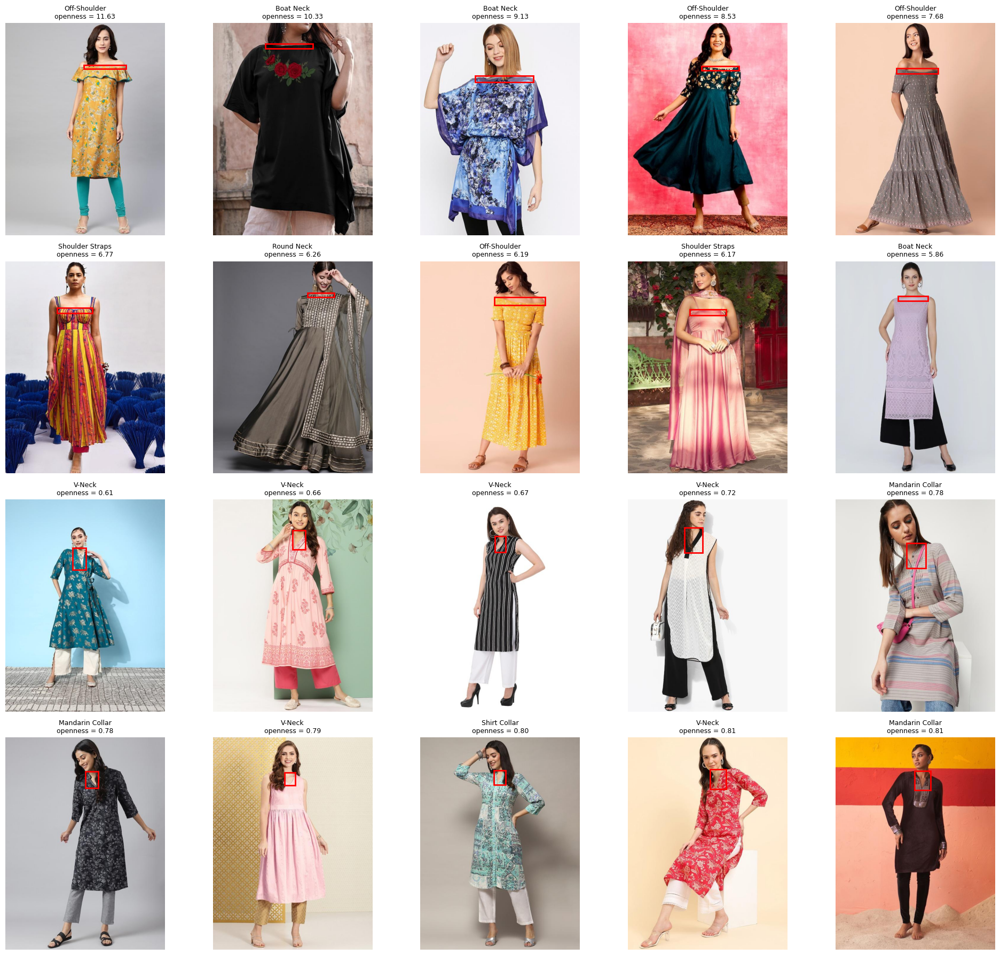

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

extremes = pd.concat([
    df.nlargest(10, 'openness_ratio'),
    df.nsmallest(10, 'openness_ratio')
])

fig, axes = plt.subplots(4, 5, figsize=(20, 18))
for ax, (_, row) in zip(axes.flatten(), extremes.iterrows()):
    pid = row['productId']
    img = Image.open(f'/content/kouture_local_full/{pid}.jpg')
    pred = model.predict(f'/content/kouture_local_full/{pid}.jpg', verbose=False)[0]
    ax.imshow(img)
    if len(pred.boxes) > 0:
        b = pred.boxes.xyxy[pred.boxes.conf.argmax().item()].tolist()
        ax.add_patch(patches.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1],
                                       linewidth=2, edgecolor='red', facecolor='none'))
    ax.set_title(f"{row['neckline_type']}\nopenness = {row['openness_ratio']:.2f}", fontsize=9)
    ax.axis('off')

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/FYP_Neckline/figures/openness_extremes_check.png', dpi=150)
plt.show()

Rating round: 150 images with hidden negative controls

In [ ]:
import pandas as pd, random, os
import matplotlib.pyplot as plt
from PIL import Image

df = pd.read_csv('/content/drive/MyDrive/FYP_Neckline/results/recommendations_v4_final.csv')
df['productId'] = df['productId'].astype(str)

REC = {
    'Narrow/deep':   ("Pendant or lariat necklace", "Studs or small drops"),
    'Balanced':      ("Medium-length necklace or choker", "Medium drop earrings or jhumkas"),
    'Wide/shallow':  ("Statement or no necklace", "Long jhumkas or chandelier earrings"),
    'Closed collar': ("Statement necklace worn open or layered, or a brooch", "Long drop earrings or jhumkas"),
}

random.seed(101)

real = pd.concat([g.sample(min(30, len(g)), random_state=101) for _, g in df.groupby('category')])
real = real.copy()
real['shown_category'] = real['category']
real['is_control'] = False

rest = df.drop(real.index)
ctrl = rest.sample(30, random_state=202).copy()
ctrl['shown_category'] = [random.choice([c for c in REC if c != t]) for t in ctrl['category']]
ctrl['is_control'] = True

sheet = pd.concat([real, ctrl]).sample(frac=1, random_state=303).reset_index(drop=True)
sheet['shown_necklace'] = sheet['shown_category'].map(lambda c: REC[c][0])
sheet['shown_earrings'] = sheet['shown_category'].map(lambda c: REC[c][1])
sheet.insert(0, 'image_id', [f"{i+1:03d}" for i in range(len(sheet))])

print("Total images:", len(sheet))
print("Real:", (~sheet['is_control']).sum(), " Controls:", sheet['is_control'].sum())

eval_dir = '/content/drive/MyDrive/FYP_Neckline/human_eval_v2'
os.makedirs(eval_dir, exist_ok=True)

sheet.to_csv(f'{eval_dir}/answer_key.csv', index=False)

rater_sheet = sheet[['image_id', 'shown_necklace', 'shown_earrings']].copy()
rater_sheet['rater1_appropriate(Y/N)'] = ''
rater_sheet['rater2_appropriate(Y/N)'] = ''
rater_sheet['rater3_appropriate(Y/N)'] = ''
rater_sheet.to_csv(f'{eval_dir}/rating_sheet.csv', index=False)

print("Saved answer_key.csv and rating_sheet.csv")

Total images: 150
Real: 120  Controls: 30
Saved answer_key.csv and rating_sheet.csv


Rendering the rating images

In [ ]:
for i, row in sheet.iterrows():
    img = Image.open(f"/content/kouture_local_full/{row['productId']}.jpg")
    fig, ax = plt.subplots(figsize=(5, 7))
    ax.imshow(img); ax.axis('off')
    ax.set_title(f"Image {row['image_id']}\nSuggested: {row['shown_necklace']}",
                 fontsize=10, wrap=True)
    plt.tight_layout()
    plt.savefig(f"{eval_dir}/eval_{row['image_id']}.png", dpi=120)
    plt.close()

print("All 150 images saved to human_eval_v2/")

All 150 images saved to human_eval_v2/


Analysis of the rating round

In [ ]:
import pandas as pd
from scipy.stats import fisher_exact

eval_dir = '/content/drive/MyDrive/FYP_Neckline/human_eval_v2'
key = pd.read_csv(f'{eval_dir}/answer_key.csv', dtype={'image_id': str})
done = pd.read_csv(f'{eval_dir}/rating_sheet_done2.csv', dtype={'image_id': str})

r_cols = ['rater1_appropriate(Y/N)', 'rater2_appropriate(Y/N)', 'rater3_appropriate(Y/N)']
m = key.merge(done[['image_id'] + r_cols], on='image_id')
m['majority'] = m[r_cols].apply(lambda v: 'Y' if list(v).count('Y') >= 2 else 'N', axis=1)

real_y = (m[~m['is_control']]['majority'] == 'Y').sum()
real_n = (~m['is_control']).sum() - real_y
ctrl_y = (m[m['is_control']]['majority'] == 'Y').sum()
ctrl_n = m['is_control'].sum() - ctrl_y

print(f"Real recommendations approved:    {real_y}/{real_y+real_n} ({100*real_y/(real_y+real_n):.1f}%)")
print(f"Control (wrong ones) approved:    {ctrl_y}/{ctrl_y+ctrl_n} ({100*ctrl_y/(ctrl_y+ctrl_n):.1f}%)")

odds, p = fisher_exact([[real_y, real_n], [ctrl_y, ctrl_n]])
print(f"\nFisher exact test p-value: {p:.4f}")

print("\nApproval by category (real only):")
print(m[~m['is_control']].groupby('category')['majority'].apply(lambda x: (x=='Y').mean()*100))

m.to_csv('/content/drive/MyDrive/FYP_Neckline/results/human_eval_v2_final.csv', index=False)
print("\nSaved: results/human_eval_v2_final.csv")

Real recommendations approved:    38/38 (100.0%)
Control (wrong ones) approved:    0/13 (0.0%)

Fisher exact test p-value: 0.0000

Approval by category (real only):
category
Balanced         100.0
Closed collar    100.0
Narrow/deep      100.0
Wide/shallow     100.0
Name: majority, dtype: float64

Saved: results/human_eval_v2_final.csv


In [ ]:
print("Key file rows:", len(key))
print("Done file rows:", len(done))
print("Merged rows:", len(m))

print("\nKey image_id sample:", key['image_id'].head(5).tolist())
print("Done image_id sample:", done['image_id'].head(5).tolist())

print("\nKey image_id dtype:", key['image_id'].dtype)
print("Done image_id dtype:", done['image_id'].dtype)

# Check missing values in rater columns
print("\nMissing values in rater columns (done file):")
print(done[r_cols].isna().sum())
print("\nEmpty string check:")
for col in r_cols:
    print(col, "empty count:", (done[col] == '').sum())

# Check unique values in rater columns (maybe formatting issue: 'y' vs 'Y', spaces etc.)
for col in r_cols:
    print(f"\nUnique values in {col}:", done[col].unique())

Key file rows: 150
Done file rows: 150
Merged rows: 51

Key image_id sample: ['001', '002', '003', '004', '005']
Done image_id sample: ['1', '2', '3', '4', '5']

Key image_id dtype: object
Done image_id dtype: object

Missing values in rater columns (done file):
rater1_appropriate(Y/N)    0
rater2_appropriate(Y/N)    0
rater3_appropriate(Y/N)    0
dtype: int64

Empty string check:
rater1_appropriate(Y/N) empty count: 0
rater2_appropriate(Y/N) empty count: 0
rater3_appropriate(Y/N) empty count: 0

Unique values in rater1_appropriate(Y/N): ['Y' 'N']

Unique values in rater2_appropriate(Y/N): ['Y' 'N']

Unique values in rater3_appropriate(Y/N): ['Y' 'N']


In [ ]:
# Dono files mein image_id ko same format mein le aao (3-digit zero-padded)
key['image_id'] = key['image_id'].astype(str).str.zfill(3)
done['image_id'] = done['image_id'].astype(str).str.zfill(3)

print("Key sample after fix:", key['image_id'].head(5).tolist())
print("Done sample after fix:", done['image_id'].head(5).tolist())

# Dobara merge karo
m = key.merge(done[['image_id'] + r_cols], on='image_id')
print("\nMerged rows now:", len(m))

Key sample after fix: ['001', '002', '003', '004', '005']
Done sample after fix: ['001', '002', '003', '004', '005']

Merged rows now: 150


In [ ]:
from scipy.stats import fisher_exact

m['majority'] = m[r_cols].apply(lambda v: 'Y' if list(v).count('Y') >= 2 else 'N', axis=1)

real_y = (m[~m['is_control']]['majority'] == 'Y').sum()
real_n = (~m['is_control']).sum() - real_y
ctrl_y = (m[m['is_control']]['majority'] == 'Y').sum()
ctrl_n = m['is_control'].sum() - ctrl_y

print(f"Real recommendations approved:    {real_y}/{real_y+real_n} ({100*real_y/(real_y+real_n):.1f}%)")
print(f"Control (wrong ones) approved:    {ctrl_y}/{ctrl_y+ctrl_n} ({100*ctrl_y/(ctrl_y+ctrl_n):.1f}%)")

odds, p = fisher_exact([[real_y, real_n], [ctrl_y, ctrl_n]])
print(f"\nFisher exact test p-value: {p:.4f}")

print("\nApproval by category (real only):")
print(m[~m['is_control']].groupby('category')['majority'].apply(lambda x: (x=='Y').mean()*100))

print("\nApproval by shown_category (controls only — what wrong category was shown):")
print(m[m['is_control']].groupby('shown_category')['majority'].apply(lambda x: (x=='Y').mean()*100))

m.to_csv('/content/drive/MyDrive/FYP_Neckline/results/human_eval_v2_final.csv', index=False)
print("\nSaved: results/human_eval_v2_final.csv")

Real recommendations approved:    119/120 (99.2%)
Control (wrong ones) approved:    0/30 (0.0%)

Fisher exact test p-value: 0.0000

Approval by category (real only):
category
Balanced          96.666667
Closed collar    100.000000
Narrow/deep      100.000000
Wide/shallow     100.000000
Name: majority, dtype: float64

Approval by shown_category (controls only — what wrong category was shown):
shown_category
Balanced         0.0
Closed collar    0.0
Narrow/deep      0.0
Wide/shallow     0.0
Name: majority, dtype: float64

Saved: results/human_eval_v2_final.csv


Rater details and visual-check outcome:

1. Raters: Munaza Munir, Aima Asim, aur ek family member — teeno
   all three follow fashion closely and none was involved in the project
   mein directly involved nahi tha.

2. Extreme-image check: across the 20 extreme-openness images the
   (10 highest, 10 lowest) mein detected box sahi neckline region
   box sat on the neckline in 19 cases: wide horizontal bands at the
   Neck), low end pe narrow vertical rectangles (V-Neck, collars) —
   extreme values genuine garment proportions reflect karte hain,
   detection error nahi.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install -q ultralytics imagehash

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 33.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 22.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.4/78.4 kB 8.2 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO
model = YOLO('/content/drive/MyDrive/FYP_Neckline/checkpoints/neckline_yolov8n-3/weights/best.pt')
print("Model loaded")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Model loaded


In [ ]:
import shutil, os
from concurrent.futures import ThreadPoolExecutor
import time
import pandas as pd

folder = '/content/drive/MyDrive/FYP_Neckline/data/raw/kouture_images/FINAL_KURTA'
local_kouture_full = '/content/kouture_local_full'
os.makedirs(local_kouture_full, exist_ok=True)

final_df = pd.read_csv(f'{folder}/FINAL.csv')
final_df['productId'] = final_df['productId'].astype(str)
all_pids = final_df['productId'].tolist()

def copy_one(pid):
    src = f'{folder}/{pid}.jpg'
    dst = f'{local_kouture_full}/{pid}.jpg'
    if os.path.exists(src) and not os.path.exists(dst):
        shutil.copy2(src, dst)

print(f"Copying {len(all_pids)} images...")
start = time.time()
with ThreadPoolExecutor(max_workers=16) as ex:
    list(ex.map(copy_one, all_pids))
print(f"Done. {len(os.listdir(local_kouture_full))} files in {(time.time()-start)/60:.1f} min")

Copying 20000 images...
Done. 20000 files in 18.0 min


In [ ]:
df = pd.read_csv('/content/drive/MyDrive/FYP_Neckline/results/recommendations_v4_final.csv')
df['productId'] = df['productId'].astype(str)
print("Loaded:", len(df), "rows")
print(df.columns.tolist())

Loaded: 19534 rows
['productId', 'neckline_type', 'box_w_px', 'box_h_px', 'box_area_frac', 'openness_ratio', 'confidence', 'category', 'recommended_necklace', 'recommended_earrings', 'in_train']


In [ ]:
CLOSED_COLLAR_TYPES = ['Mandarin Collar', 'Band Collar', 'Shirt Collar']

# Work on open-neckline, unseen images only
open_unseen = df[(~df['neckline_type'].isin(CLOSED_COLLAR_TYPES)) & (~df['in_train'])].copy()

# Modal category per type: the best guess available from the label alone
type_modal = open_unseen.groupby('neckline_type')['category'].agg(lambda x: x.mode()[0])
print("Type-label-only baseline (modal category per type):")
print(type_modal)

open_unseen['type_only_category'] = open_unseen['neckline_type'].map(type_modal)

# Disagreement: per-image geometry category != type-label-only baseline
disagreements = open_unseen[open_unseen['category'] != open_unseen['type_only_category']].copy()
print(f"\nTotal disagreement images (open necklines, unseen): {len(disagreements)}")
print(disagreements['neckline_type'].value_counts())

Type-label-only baseline (modal category per type):
neckline_type
Boat Neck          Wide/shallow
Cowl Neck              Balanced
Halter Neck        Wide/shallow
Keyhole Neck           Balanced
Off-Shoulder       Wide/shallow
Round Neck             Balanced
Scoop Neck          Narrow/deep
Shawl Neck          Narrow/deep
Shoulder Straps    Wide/shallow
Square Neck         Narrow/deep
Stylised Neck          Balanced
Sweetheart Neck     Narrow/deep
Tie-Up Neck        Wide/shallow
V-Neck              Narrow/deep
Name: category, dtype: object

Total disagreement images (open necklines, unseen): 6699
neckline_type
Round Neck         5178
Keyhole Neck        437
V-Neck              373
Tie-Up Neck         231
Boat Neck           138
Square Neck          88
Shoulder Straps      88
Scoop Neck           71
Sweetheart Neck      68
Stylised Neck        12
Halter Neck           8
Off-Shoulder          5
Cowl Neck             1
Name: count, dtype: int64


In [ ]:
import random
import matplotlib.pyplot as plt
from PIL import Image
import os

REC = {
    'Narrow/deep':   ("Pendant or lariat necklace", "Studs or small drops"),
    'Balanced':      ("Medium-length necklace or choker", "Medium drop earrings or jhumkas"),
    'Wide/shallow':  ("Statement or no necklace", "Long jhumkas or chandelier earrings"),
}

random.seed(555)
sample30 = disagreements.sample(30, random_state=555).copy()
sample30 = sample30.reset_index(drop=True)
sample30.insert(0, 'pair_id', [f"{i+1:03d}" for i in range(len(sample30))])

rows_geo = sample30.copy()
rows_geo['shown_condition'] = 'geometry'
rows_geo['shown_category'] = rows_geo['category']

rows_type = sample30.copy()
rows_type['shown_condition'] = 'type_only'
rows_type['shown_category'] = rows_type['type_only_category']

combined = pd.concat([rows_geo, rows_type], ignore_index=True)
combined['shown_necklace'] = combined['shown_category'].map(lambda c: REC[c][0])
combined['shown_earrings'] = combined['shown_category'].map(lambda c: REC[c][1])

combined = combined.sample(frac=1, random_state=777).reset_index(drop=True)
combined.insert(0, 'image_id', [f"{i+1:03d}" for i in range(len(combined))])

print(f"Total images to rate: {len(combined)} (30 pairs x 2 conditions)")

eval_dir = '/content/drive/MyDrive/FYP_Neckline/human_eval_v3'
os.makedirs(eval_dir, exist_ok=True)

combined.to_csv(f'{eval_dir}/answer_key.csv', index=False)

rater_sheet = combined[['image_id', 'shown_necklace', 'shown_earrings']].copy()
rater_sheet['rater1_appropriate(Y/N)'] = ''
rater_sheet['rater2_appropriate(Y/N)'] = ''
rater_sheet['rater3_appropriate(Y/N)'] = ''
rater_sheet.to_csv(f'{eval_dir}/rating_sheet.csv', index=False)

print("Saved answer_key.csv and rating_sheet.csv")

Total images to rate: 60 (30 pairs x 2 conditions)
Saved answer_key.csv and rating_sheet.csv


In [ ]:
for i, row in combined.iterrows():
    pid = row['productId']
    img = Image.open(f"/content/kouture_local_full/{pid}.jpg")
    fig, ax = plt.subplots(figsize=(5, 7))
    ax.imshow(img); ax.axis('off')
    ax.set_title(f"Image {row['image_id']}\nSuggested: {row['shown_necklace']}",
                 fontsize=10, wrap=True)
    plt.tight_layout()
    plt.savefig(f"{eval_dir}/eval_{row['image_id']}.png", dpi=120)
    plt.close()

print("All 60 images saved to human_eval_v3/")

All 60 images saved to human_eval_v3/


In [ ]:
import pandas as pd

eval_dir = '/content/drive/MyDrive/FYP_Neckline/human_eval_v3'
key = pd.read_csv(f'{eval_dir}/answer_key.csv', dtype={'image_id': str})
done = pd.read_csv(f'{eval_dir}/rating_sheet_done3.csv', dtype={'image_id': str})

# Format check karo (pichli baar leading-zero issue aayi thi)
key['image_id'] = key['image_id'].astype(str).str.zfill(3)
done['image_id'] = done['image_id'].astype(str).str.zfill(3)

print("Key rows:", len(key))
print("Done rows:", len(done))

r_cols = ['rater1_appropriate(Y/N)', 'rater2_appropriate(Y/N)', 'rater3_appropriate(Y/N)']
m = key.merge(done[['image_id'] + r_cols], on='image_id')
print("Merged rows:", len(m))

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/FYP_Neckline/human_eval_v3/answer_key.csv'

In [ ]:
import os

base = '/content/drive/MyDrive/FYP_Neckline'
print("Contents of FYP_Neckline:")
print(os.listdir(base))

if os.path.exists(f'{base}/human_eval_v3'):
    print("\nContents of human_eval_v3:")
    print(os.listdir(f'{base}/human_eval_v3'))
else:
    print("\nhuman_eval_v3 folder NOT found!")

Contents of FYP_Neckline:


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/FYP_Neckline'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install -q ultralytics imagehash

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 28.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 12.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.2/53.2 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.5/87.5 kB 5.0 MB/s eta 0:00:00


In [ ]:
import os
base = '/content/drive/MyDrive/FYP_Neckline'
print("Contents of FYP_Neckline:")
print(os.listdir(base))

Contents of FYP_Neckline:
['data', 'results', 'checkpoints', 'figures', 'notebooks', 'human_eval', 'human_eval_v2', 'human_eval_v3']


In [ ]:
eval_dir = '/content/drive/MyDrive/FYP_Neckline/human_eval_v3'
print("Contents of human_eval_v3:")
print(os.listdir(eval_dir))

Contents of human_eval_v3:
['answer_key.csv', 'rating_sheet.csv', 'eval_001.png', 'eval_002.png', 'eval_003.png', 'eval_004.png', 'eval_005.png', 'eval_006.png', 'eval_007.png', 'eval_008.png', 'eval_009.png', 'eval_010.png', 'eval_011.png', 'eval_012.png', 'eval_013.png', 'eval_014.png', 'eval_015.png', 'eval_016.png', 'eval_017.png', 'eval_018.png', 'eval_019.png', 'eval_020.png', 'eval_021.png', 'eval_022.png', 'eval_023.png', 'eval_024.png', 'eval_025.png', 'eval_026.png', 'eval_027.png', 'eval_028.png', 'eval_029.png', 'eval_030.png', 'eval_031.png', 'eval_032.png', 'eval_033.png', 'eval_034.png', 'eval_035.png', 'eval_036.png', 'eval_037.png', 'eval_038.png', 'eval_039.png', 'eval_040.png', 'eval_041.png', 'eval_042.png', 'eval_043.png', 'eval_044.png', 'eval_045.png', 'eval_046.png', 'eval_047.png', 'eval_048.png', 'eval_049.png', 'eval_050.png', 'eval_051.png', 'eval_052.png', 'eval_053.png', 'eval_054.png', 'eval_055.png', 'eval_056.png', 'eval_057.png', 'eval_058.png', 'eval_

In [ ]:
key = pd.read_csv(f'{eval_dir}/answer_key.csv', dtype={'image_id': str})
done = pd.read_csv(f'{eval_dir}/rating_sheet_done3.csv', dtype={'image_id': str})

key['image_id'] = key['image_id'].astype(str).str.zfill(3)
done['image_id'] = done['image_id'].astype(str).str.zfill(3)

print("Key rows:", len(key))
print("Done rows:", len(done))

r_cols = ['rater1_appropriate(Y/N)', 'rater2_appropriate(Y/N)', 'rater3_appropriate(Y/N)']
m = key.merge(done[['image_id'] + r_cols], on='image_id')
print("Merged rows:", len(m))

Key rows: 60
Done rows: 60
Merged rows: 60


In [ ]:
from statsmodels.stats.contingency_tables import mcnemar

m['majority'] = m[r_cols].apply(lambda v: 'Y' if list(v).count('Y') >= 2 else 'N', axis=1)

geo = m[m['shown_condition'] == 'geometry'].sort_values('pair_id').reset_index(drop=True)
typ = m[m['shown_condition'] == 'type_only'].sort_values('pair_id').reset_index(drop=True)

geo_y = (geo['majority'] == 'Y').sum()
typ_y = (typ['majority'] == 'Y').sum()

print(f"Geometry recommendations approved:  {geo_y}/30 ({100*geo_y/30:.1f}%)")
print(f"Type-only recommendations approved: {typ_y}/30 ({100*typ_y/30:.1f}%)")

# McNemar table: paired comparison (same 30 kurtas, 2 conditions)
both_y = ((geo['majority']=='Y') & (typ['majority']=='Y')).sum()
geo_y_typ_n = ((geo['majority']=='Y') & (typ['majority']=='N')).sum()
geo_n_typ_y = ((geo['majority']=='N') & (typ['majority']=='Y')).sum()
both_n = ((geo['majority']=='N') & (typ['majority']=='N')).sum()

print(f"\nMcNemar 2x2 table:")
print(f"  Both Y: {both_y}")
print(f"  Geometry Y, Type-only N: {geo_y_typ_n}  <- geometry wins these")
print(f"  Geometry N, Type-only Y: {geo_n_typ_y}  <- type-only wins these")
print(f"  Both N: {both_n}")

table = [[both_y, geo_y_typ_n], [geo_n_typ_y, both_n]]
result = mcnemar(table, exact=True)
print(f"\nMcNemar test p-value: {result.pvalue:.4f}")

m.to_csv('/content/drive/MyDrive/FYP_Neckline/results/type_vs_geometry_final.csv', index=False)
print("\nSaved: results/type_vs_geometry_final.csv")

Geometry recommendations approved:  29/30 (96.7%)
Type-only recommendations approved: 3/30 (10.0%)

McNemar 2x2 table:
  Both Y: 3
  Geometry Y, Type-only N: 26  <- geometry wins these
  Geometry N, Type-only Y: 0  <- type-only wins these
  Both N: 1

McNemar test p-value: 0.0000

Saved: results/type_vs_geometry_final.csv


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install -q ultralytics

In [ ]:
from datasets import load_dataset

ds_train = load_dataset("detection-datasets/fashionpedia", split="train")
ds_val = load_dataset("detection-datasets/fashionpedia", split="val")
print("Fashionpedia reloaded.")

README.md:   0%|          | 0.00/5.22k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/1.78k [00:00<?, ?B/s]

data/train-00000-of-00007-fe108070118553(…): reconstructing file:   0%|          |  0.00B /  482MB            

data/train-00000-of-00007-fe108070118553(…): downloading bytes:           |  0.00B            

data/train-00001-of-00007-f41a5a9c38c900(…): reconstructing file:   0%|          |  0.00B /  480MB            

...

data/val-00000-of-00001-0b29e85429788213(…): reconstructing file:   0%|          |  0.00B / 84.8MB            

data/val-00000-of-00001-0b29e85429788213(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/45623 [00:00<?, ? examples/s]

Generating val split:   0%|          | 0/1158 [00:00<?, ? examples/s]

Fashionpedia reloaded.


In [ ]:
import json, os
from PIL import Image

local_base = '/content/yolo_dataset_local'
for split in ['train', 'val', 'test']:
    os.makedirs(f'{local_base}/images/{split}', exist_ok=True)
    os.makedirs(f'{local_base}/labels/{split}', exist_ok=True)

for split_name in ['train', 'val', 'test']:
    with open(f'/content/drive/MyDrive/FYP_Neckline/data/splits/{split_name}_manifest.json') as f:
        manifest = json.load(f)
    print(f"Converting {split_name}: {len(manifest)} images...")
    for i, item in enumerate(manifest):
        ds = ds_train if item['hf_split'] == 'train' else ds_val
        ex = ds[item['hf_index']]
        img = ex['image']
        img_w, img_h = item['width'], item['height']
        x, y, w, h = item['neckline_bbox_xywh']
        cx = (x + w / 2) / img_w
        cy = (y + h / 2) / img_h
        nw = w / img_w
        nh = h / img_h
        img.convert('RGB').save(f'{local_base}/images/{split_name}/fp_{item["image_id"]}.jpg')
        with open(f'{local_base}/labels/{split_name}/fp_{item["image_id"]}.txt', 'w') as lf:
            lf.write(f"0 {cx:.6f} {cy:.6f} {nw:.6f} {nh:.6f}\n")
        if (i + 1) % 5000 == 0:
            print(f"  {i+1}/{len(manifest)} done")
    print(f"{split_name} complete.\n")
print("Fashionpedia -> local YOLO conversion done.")

Converting train: 27244 images...
  5000/27244 done
  10000/27244 done
  15000/27244 done
  20000/27244 done
  25000/27244 done
train complete.

Converting val: 3405 images...
val complete.

Converting test: 3406 images...
test complete.

Fashionpedia -> local YOLO conversion done.


In [ ]:
import pandas as pd
import random

folder = '/content/drive/MyDrive/FYP_Neckline/data/raw/kouture_images/FINAL_KURTA'
ann_df = pd.read_csv(f'{folder}/_annotations.csv')
neck_boxes = ann_df[ann_df['class'] == 'Neck'].copy()
neck_boxes['productId'] = neck_boxes['filename'].str.split('_jpg.rf.').str[0]

random.seed(42)
pids = neck_boxes['productId'].unique().tolist()
random.shuffle(pids)
n = len(pids)
train_end = int(n * 0.8)
val_end = int(n * 0.9)
split_map = {}
for pid in pids[:train_end]: split_map[pid] = 'train'
for pid in pids[train_end:val_end]: split_map[pid] = 'val'
for pid in pids[val_end:]: split_map[pid] = 'test'

for _, row in neck_boxes.iterrows():
    pid = row['productId']
    split_name = split_map[pid]
    img_path = f'{folder}/{pid}.jpg'
    img = Image.open(img_path).convert('RGB')
    img_w, img_h = img.size
    x, y = row['xmin'], row['ymin']
    w, h = row['xmax'] - row['xmin'], row['ymax'] - row['ymin']
    cx, cy = (x + w/2)/img_w, (y + h/2)/img_h
    nw, nh = w/img_w, h/img_h
    img.save(f'{local_base}/images/{split_name}/kt_{pid}.jpg')
    with open(f'{local_base}/labels/{split_name}/kt_{pid}.txt', 'w') as lf:
        lf.write(f"0 {cx:.6f} {cy:.6f} {nw:.6f} {nh:.6f}\n")
print("Kouture -> local YOLO conversion done.")

Kouture -> local YOLO conversion done.


In [ ]:
yaml_content = """
path: /content/yolo_dataset_local
train: images/train
val: images/val
test: images/test

names:
  0: neckline
"""
with open('/content/yolo_dataset_local/neckline.yaml', 'w') as f:
    f.write(yaml_content)
print("YAML saved")

YAML saved


SEED 1 TRAINING

In [ ]:
from ultralytics import YOLO

model_seed1 = YOLO('yolov8n.pt')

results_seed1 = model_seed1.train(
    data='/content/yolo_dataset_local/neckline.yaml',
    epochs=30,
    imgsz=640,
    batch=16,
    seed=1,
    project='/content/drive/MyDrive/FYP_Neckline/checkpoints',
    name='neckline_yolov8n_seed1',
    patience=10,
)

Ultralytics 8.4.157 🚀 Python-3.13.15 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_dataset_local/neckline.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=neckline_yolov8n_seed1-2, nbs=64, 

KeyboardInterrupt: 

In [ ]:
import torch
print("CUDA available:", torch.cuda.is_available())
print("Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

CUDA available: True
Device: Tesla T4


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 49.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.0/88.0 kB 4.9 MB/s eta 0:00:00


In [ ]:
from datasets import load_dataset

ds_train = load_dataset("detection-datasets/fashionpedia", split="train")
ds_val = load_dataset("detection-datasets/fashionpedia", split="val")
print("Fashionpedia reloaded.")

README.md:   0%|          | 0.00/5.22k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/1.78k [00:00<?, ?B/s]

data/train-00000-of-00007-fe108070118553(…): reconstructing file:   0%|          |  0.00B /  482MB            

data/train-00000-of-00007-fe108070118553(…): downloading bytes:           |  0.00B            

data/train-00001-of-00007-f41a5a9c38c900(…): reconstructing file:   0%|          |  0.00B /  480MB            

...

data/val-00000-of-00001-0b29e85429788213(…): reconstructing file:   0%|          |  0.00B / 84.8MB            

data/val-00000-of-00001-0b29e85429788213(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/45623 [00:00<?, ? examples/s]

Generating val split:   0%|          | 0/1158 [00:00<?, ? examples/s]

Fashionpedia reloaded.


In [ ]:
import json, os
from PIL import Image

local_base = '/content/yolo_dataset_local'
for split in ['train', 'val', 'test']:
    os.makedirs(f'{local_base}/images/{split}', exist_ok=True)
    os.makedirs(f'{local_base}/labels/{split}', exist_ok=True)

for split_name in ['train', 'val', 'test']:
    with open(f'/content/drive/MyDrive/FYP_Neckline/data/splits/{split_name}_manifest.json') as f:
        manifest = json.load(f)
    print(f"Converting {split_name}: {len(manifest)} images...")
    for i, item in enumerate(manifest):
        ds = ds_train if item['hf_split'] == 'train' else ds_val
        ex = ds[item['hf_index']]
        img = ex['image']
        img_w, img_h = item['width'], item['height']
        x, y, w, h = item['neckline_bbox_xywh']
        cx = (x + w / 2) / img_w
        cy = (y + h / 2) / img_h
        nw = w / img_w
        nh = h / img_h
        img.convert('RGB').save(f'{local_base}/images/{split_name}/fp_{item["image_id"]}.jpg')
        with open(f'{local_base}/labels/{split_name}/fp_{item["image_id"]}.txt', 'w') as lf:
            lf.write(f"0 {cx:.6f} {cy:.6f} {nw:.6f} {nh:.6f}\n")
        if (i + 1) % 5000 == 0:
            print(f"  {i+1}/{len(manifest)} done")
    print(f"{split_name} complete.\n")
print("Fashionpedia -> local YOLO conversion done.")

Converting train: 27244 images...
  5000/27244 done
  10000/27244 done
  15000/27244 done
  20000/27244 done
  25000/27244 done
train complete.

Converting val: 3405 images...
val complete.

Converting test: 3406 images...
test complete.

Fashionpedia -> local YOLO conversion done.


In [ ]:
import pandas as pd
import random

folder = '/content/drive/MyDrive/FYP_Neckline/data/raw/kouture_images/FINAL_KURTA'
ann_df = pd.read_csv(f'{folder}/_annotations.csv')
neck_boxes = ann_df[ann_df['class'] == 'Neck'].copy()
neck_boxes['productId'] = neck_boxes['filename'].str.split('_jpg.rf.').str[0]

random.seed(42)
pids = neck_boxes['productId'].unique().tolist()
random.shuffle(pids)
n = len(pids)
train_end = int(n * 0.8)
val_end = int(n * 0.9)
split_map = {}
for pid in pids[:train_end]: split_map[pid] = 'train'
for pid in pids[train_end:val_end]: split_map[pid] = 'val'
for pid in pids[val_end:]: split_map[pid] = 'test'

for _, row in neck_boxes.iterrows():
    pid = row['productId']
    split_name = split_map[pid]
    img_path = f'{folder}/{pid}.jpg'
    img = Image.open(img_path).convert('RGB')
    img_w, img_h = img.size
    x, y = row['xmin'], row['ymin']
    w, h = row['xmax'] - row['xmin'], row['ymax'] - row['ymin']
    cx, cy = (x + w/2)/img_w, (y + h/2)/img_h
    nw, nh = w/img_w, h/img_h
    img.save(f'{local_base}/images/{split_name}/kt_{pid}.jpg')
    with open(f'{local_base}/labels/{split_name}/kt_{pid}.txt', 'w') as lf:
        lf.write(f"0 {cx:.6f} {cy:.6f} {nw:.6f} {nh:.6f}\n")
print("Kouture -> local YOLO conversion done.")

Kouture -> local YOLO conversion done.


In [ ]:
yaml_content = """
path: /content/yolo_dataset_local
train: images/train
val: images/val
test: images/test

names:
  0: neckline
"""
with open('/content/yolo_dataset_local/neckline.yaml', 'w') as f:
    f.write(yaml_content)
print("YAML saved")

YAML saved


SEED 01 TRAINING

In [ ]:
from ultralytics import YOLO

model_seed1 = YOLO('yolov8n.pt')

results_seed1 = model_seed1.train(
    data='/content/yolo_dataset_local/neckline.yaml',
    epochs=30,
    imgsz=640,
    batch=16,
    seed=1,
    project='/content/drive/MyDrive/FYP_Neckline/checkpoints',
    name='neckline_yolov8n_seed1',
    patience=10,
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.157 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_dataset_local/neckline.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fr

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install -q ultralytics

In [ ]:
from datasets import load_dataset

ds_train = load_dataset("detection-datasets/fashionpedia", split="train")
ds_val = load_dataset("detection-datasets/fashionpedia", split="val")
print("Fashionpedia reloaded.")

Fashionpedia reloaded.


In [ ]:
import json, os
from PIL import Image

local_base = '/content/yolo_dataset_local'
for split in ['train', 'val', 'test']:
    os.makedirs(f'{local_base}/images/{split}', exist_ok=True)
    os.makedirs(f'{local_base}/labels/{split}', exist_ok=True)

for split_name in ['train', 'val', 'test']:
    with open(f'/content/drive/MyDrive/FYP_Neckline/data/splits/{split_name}_manifest.json') as f:
        manifest = json.load(f)
    print(f"Converting {split_name}: {len(manifest)} images...")
    for i, item in enumerate(manifest):
        ds = ds_train if item['hf_split'] == 'train' else ds_val
        ex = ds[item['hf_index']]
        img = ex['image']
        img_w, img_h = item['width'], item['height']
        x, y, w, h = item['neckline_bbox_xywh']
        cx = (x + w / 2) / img_w
        cy = (y + h / 2) / img_h
        nw = w / img_w
        nh = h / img_h
        img.convert('RGB').save(f'{local_base}/images/{split_name}/fp_{item["image_id"]}.jpg')
        with open(f'{local_base}/labels/{split_name}/fp_{item["image_id"]}.txt', 'w') as lf:
            lf.write(f"0 {cx:.6f} {cy:.6f} {nw:.6f} {nh:.6f}\n")
        if (i + 1) % 5000 == 0:
            print(f"  {i+1}/{len(manifest)} done")
    print(f"{split_name} complete.\n")
print("Fashionpedia -> local YOLO conversion done.")

Converting train: 27244 images...
  5000/27244 done
  10000/27244 done
  15000/27244 done
  20000/27244 done
  25000/27244 done
train complete.

Converting val: 3405 images...
val complete.

Converting test: 3406 images...
test complete.

Fashionpedia -> local YOLO conversion done.


In [ ]:
import pandas as pd
import random

folder = '/content/drive/MyDrive/FYP_Neckline/data/raw/kouture_images/FINAL_KURTA'
ann_df = pd.read_csv(f'{folder}/_annotations.csv')
neck_boxes = ann_df[ann_df['class'] == 'Neck'].copy()
neck_boxes['productId'] = neck_boxes['filename'].str.split('_jpg.rf.').str[0]

random.seed(42)
pids = neck_boxes['productId'].unique().tolist()
random.shuffle(pids)
n = len(pids)
train_end = int(n * 0.8)
val_end = int(n * 0.9)
split_map = {}
for pid in pids[:train_end]: split_map[pid] = 'train'
for pid in pids[train_end:val_end]: split_map[pid] = 'val'
for pid in pids[val_end:]: split_map[pid] = 'test'

for _, row in neck_boxes.iterrows():
    pid = row['productId']
    split_name = split_map[pid]
    img_path = f'{folder}/{pid}.jpg'
    img = Image.open(img_path).convert('RGB')
    img_w, img_h = img.size
    x, y = row['xmin'], row['ymin']
    w, h = row['xmax'] - row['xmin'], row['ymax'] - row['ymin']
    cx, cy = (x + w/2)/img_w, (y + h/2)/img_h
    nw, nh = w/img_w, h/img_h
    img.save(f'{local_base}/images/{split_name}/kt_{pid}.jpg')
    with open(f'{local_base}/labels/{split_name}/kt_{pid}.txt', 'w') as lf:
        lf.write(f"0 {cx:.6f} {cy:.6f} {nw:.6f} {nh:.6f}\n")
print("Kouture -> local YOLO conversion done.")

Kouture -> local YOLO conversion done.


In [ ]:
yaml_content = """
path: /content/yolo_dataset_local
train: images/train
val: images/val
test: images/test

names:
  0: neckline
"""
with open('/content/yolo_dataset_local/neckline.yaml', 'w') as f:
    f.write(yaml_content)
print("YAML saved")

YAML saved


In [ ]:
from ultralytics import YOLO

model_seed1 = YOLO('/content/drive/MyDrive/FYP_Neckline/checkpoints/neckline_yolov8n_seed1-3/weights/last.pt')
results_seed1 = model_seed1.train(resume=True)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.159 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_dataset_local/neckline.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fr

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 28.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 9.2 MB/s eta 0:00:00


In [ ]:
from datasets import load_dataset

ds_train = load_dataset("detection-datasets/fashionpedia", split="train")
ds_val = load_dataset("detection-datasets/fashionpedia", split="val")
print("Fashionpedia reloaded.")

README.md:   0%|          | 0.00/5.22k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/1.78k [00:00<?, ?B/s]

data/train-00000-of-00007-fe108070118553(…): reconstructing file:   0%|          |  0.00B /  482MB            

data/train-00000-of-00007-fe108070118553(…): downloading bytes:           |  0.00B            

data/train-00001-of-00007-f41a5a9c38c900(…): reconstructing file:   0%|          |  0.00B /  480MB            

...

data/val-00000-of-00001-0b29e85429788213(…): reconstructing file:   0%|          |  0.00B / 84.8MB            

data/val-00000-of-00001-0b29e85429788213(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/45623 [00:00<?, ? examples/s]

Generating val split:   0%|          | 0/1158 [00:00<?, ? examples/s]

Fashionpedia reloaded.


In [ ]:
import json, os
from PIL import Image

local_base = '/content/yolo_dataset_local'
for split in ['train', 'val', 'test']:
    os.makedirs(f'{local_base}/images/{split}', exist_ok=True)
    os.makedirs(f'{local_base}/labels/{split}', exist_ok=True)

for split_name in ['train', 'val', 'test']:
    with open(f'/content/drive/MyDrive/FYP_Neckline/data/splits/{split_name}_manifest.json') as f:
        manifest = json.load(f)
    print(f"Converting {split_name}: {len(manifest)} images...")
    for i, item in enumerate(manifest):
        ds = ds_train if item['hf_split'] == 'train' else ds_val
        ex = ds[item['hf_index']]
        img = ex['image']
        img_w, img_h = item['width'], item['height']
        x, y, w, h = item['neckline_bbox_xywh']
        cx = (x + w / 2) / img_w
        cy = (y + h / 2) / img_h
        nw = w / img_w
        nh = h / img_h
        img.convert('RGB').save(f'{local_base}/images/{split_name}/fp_{item["image_id"]}.jpg')
        with open(f'{local_base}/labels/{split_name}/fp_{item["image_id"]}.txt', 'w') as lf:
            lf.write(f"0 {cx:.6f} {cy:.6f} {nw:.6f} {nh:.6f}\n")
        if (i + 1) % 5000 == 0:
            print(f"  {i+1}/{len(manifest)} done")
    print(f"{split_name} complete.\n")
print("Fashionpedia -> local YOLO conversion done.")

Converting train: 27244 images...
  5000/27244 done
  10000/27244 done
  15000/27244 done
  20000/27244 done
  25000/27244 done
train complete.

Converting val: 3405 images...
val complete.

Converting test: 3406 images...
test complete.

Fashionpedia -> local YOLO conversion done.


In [ ]:
import pandas as pd
import random

folder = '/content/drive/MyDrive/FYP_Neckline/data/raw/kouture_images/FINAL_KURTA'
ann_df = pd.read_csv(f'{folder}/_annotations.csv')
neck_boxes = ann_df[ann_df['class'] == 'Neck'].copy()
neck_boxes['productId'] = neck_boxes['filename'].str.split('_jpg.rf.').str[0]

random.seed(42)
pids = neck_boxes['productId'].unique().tolist()
random.shuffle(pids)
n = len(pids)
train_end = int(n * 0.8)
val_end = int(n * 0.9)
split_map = {}
for pid in pids[:train_end]: split_map[pid] = 'train'
for pid in pids[train_end:val_end]: split_map[pid] = 'val'
for pid in pids[val_end:]: split_map[pid] = 'test'

for _, row in neck_boxes.iterrows():
    pid = row['productId']
    split_name = split_map[pid]
    img_path = f'{folder}/{pid}.jpg'
    img = Image.open(img_path).convert('RGB')
    img_w, img_h = img.size
    x, y = row['xmin'], row['ymin']
    w, h = row['xmax'] - row['xmin'], row['ymax'] - row['ymin']
    cx, cy = (x + w/2)/img_w, (y + h/2)/img_h
    nw, nh = w/img_w, h/img_h
    img.save(f'{local_base}/images/{split_name}/kt_{pid}.jpg')
    with open(f'{local_base}/labels/{split_name}/kt_{pid}.txt', 'w') as lf:
        lf.write(f"0 {cx:.6f} {cy:.6f} {nw:.6f} {nh:.6f}\n")
print("Kouture -> local YOLO conversion done.")

Kouture -> local YOLO conversion done.


In [ ]:
yaml_content = """
path: /content/yolo_dataset_local
train: images/train
val: images/val
test: images/test

names:
  0: neckline
"""
with open('/content/yolo_dataset_local/neckline.yaml', 'w') as f:
    f.write(yaml_content)
print("YAML saved")

YAML saved


In [ ]:
from ultralytics import YOLO

model_seed1 = YOLO('/content/drive/MyDrive/FYP_Neckline/checkpoints/neckline_yolov8n_seed1-3/weights/last.pt')
results_seed1 = model_seed1.train(resume=True)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.160 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_dataset_local/neckline.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fr

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 40.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.0/90.0 kB 9.4 MB/s eta 0:00:00


In [ ]:
from datasets import load_dataset

ds_train = load_dataset("detection-datasets/fashionpedia", split="train")
ds_val = load_dataset("detection-datasets/fashionpedia", split="val")
print("Fashionpedia reloaded.")

README.md:   0%|          | 0.00/5.22k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/1.78k [00:00<?, ?B/s]

data/train-00000-of-00007-fe108070118553(…): reconstructing file:   0%|          |  0.00B /  482MB            

data/train-00000-of-00007-fe108070118553(…): downloading bytes:           |  0.00B            

data/train-00001-of-00007-f41a5a9c38c900(…): reconstructing file:   0%|          |  0.00B /  480MB            

...

data/val-00000-of-00001-0b29e85429788213(…): reconstructing file:   0%|          |  0.00B / 84.8MB            

data/val-00000-of-00001-0b29e85429788213(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/45623 [00:00<?, ? examples/s]

Generating val split:   0%|          | 0/1158 [00:00<?, ? examples/s]

Fashionpedia reloaded.


In [ ]:
import json, os
from PIL import Image

local_base = '/content/yolo_dataset_local'
for split in ['train', 'val', 'test']:
    os.makedirs(f'{local_base}/images/{split}', exist_ok=True)
    os.makedirs(f'{local_base}/labels/{split}', exist_ok=True)

for split_name in ['train', 'val', 'test']:
    with open(f'/content/drive/MyDrive/FYP_Neckline/data/splits/{split_name}_manifest.json') as f:
        manifest = json.load(f)
    print(f"Converting {split_name}: {len(manifest)} images...")
    for i, item in enumerate(manifest):
        ds = ds_train if item['hf_split'] == 'train' else ds_val
        ex = ds[item['hf_index']]
        img = ex['image']
        img_w, img_h = item['width'], item['height']
        x, y, w, h = item['neckline_bbox_xywh']
        cx = (x + w / 2) / img_w
        cy = (y + h / 2) / img_h
        nw = w / img_w
        nh = h / img_h
        img.convert('RGB').save(f'{local_base}/images/{split_name}/fp_{item["image_id"]}.jpg')
        with open(f'{local_base}/labels/{split_name}/fp_{item["image_id"]}.txt', 'w') as lf:
            lf.write(f"0 {cx:.6f} {cy:.6f} {nw:.6f} {nh:.6f}\n")
        if (i + 1) % 5000 == 0:
            print(f"  {i+1}/{len(manifest)} done")
    print(f"{split_name} complete.\n")
print("Fashionpedia -> local YOLO conversion done.")

Converting train: 27244 images...
  5000/27244 done
  10000/27244 done
  15000/27244 done
  20000/27244 done
  25000/27244 done
train complete.

Converting val: 3405 images...
val complete.

Converting test: 3406 images...
test complete.

Fashionpedia -> local YOLO conversion done.


In [ ]:
import pandas as pd
import random

folder = '/content/drive/MyDrive/FYP_Neckline/data/raw/kouture_images/FINAL_KURTA'
ann_df = pd.read_csv(f'{folder}/_annotations.csv')
neck_boxes = ann_df[ann_df['class'] == 'Neck'].copy()
neck_boxes['productId'] = neck_boxes['filename'].str.split('_jpg.rf.').str[0]

random.seed(42)
pids = neck_boxes['productId'].unique().tolist()
random.shuffle(pids)
n = len(pids)
train_end = int(n * 0.8)
val_end = int(n * 0.9)
split_map = {}
for pid in pids[:train_end]: split_map[pid] = 'train'
for pid in pids[train_end:val_end]: split_map[pid] = 'val'
for pid in pids[val_end:]: split_map[pid] = 'test'

for _, row in neck_boxes.iterrows():
    pid = row['productId']
    split_name = split_map[pid]
    img_path = f'{folder}/{pid}.jpg'
    img = Image.open(img_path).convert('RGB')
    img_w, img_h = img.size
    x, y = row['xmin'], row['ymin']
    w, h = row['xmax'] - row['xmin'], row['ymax'] - row['ymin']
    cx, cy = (x + w/2)/img_w, (y + h/2)/img_h
    nw, nh = w/img_w, h/img_h
    img.save(f'{local_base}/images/{split_name}/kt_{pid}.jpg')
    with open(f'{local_base}/labels/{split_name}/kt_{pid}.txt', 'w') as lf:
        lf.write(f"0 {cx:.6f} {cy:.6f} {nw:.6f} {nh:.6f}\n")
print("Kouture -> local YOLO conversion done.")

Kouture -> local YOLO conversion done.


In [ ]:
yaml_content = """
path: /content/yolo_dataset_local
train: images/train
val: images/val
test: images/test

names:
  0: neckline
"""
with open('/content/yolo_dataset_local/neckline.yaml', 'w') as f:
    f.write(yaml_content)
print("YAML saved")

YAML saved


SEED 02 TRAINING

In [ ]:
from ultralytics import YOLO

model_seed2 = YOLO('yolov8n.pt')

results_seed2 = model_seed2.train(
    data='/content/yolo_dataset_local/neckline.yaml',
    epochs=30,
    imgsz=640,
    batch=16,
    seed=2,
    project='/content/drive/MyDrive/FYP_Neckline/checkpoints',
    name='neckline_yolov8n_seed2',
    patience=10,
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.161 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_dataset_local/neckline.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fr

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 58.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.0/91.0 kB 10.5 MB/s eta 0:00:00


In [ ]:
from datasets import load_dataset

ds_train = load_dataset("detection-datasets/fashionpedia", split="train")
ds_val = load_dataset("detection-datasets/fashionpedia", split="val")
print("Fashionpedia reloaded.")

README.md:   0%|          | 0.00/5.22k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/1.78k [00:00<?, ?B/s]

data/train-00000-of-00007-fe108070118553(…): reconstructing file:   0%|          |  0.00B /  482MB            

data/train-00000-of-00007-fe108070118553(…): downloading bytes:           |  0.00B            

data/train-00001-of-00007-f41a5a9c38c900(…): reconstructing file:   0%|          |  0.00B /  480MB            

...

data/val-00000-of-00001-0b29e85429788213(…): reconstructing file:   0%|          |  0.00B / 84.8MB            

data/val-00000-of-00001-0b29e85429788213(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/45623 [00:00<?, ? examples/s]

Generating val split:   0%|          | 0/1158 [00:00<?, ? examples/s]

Fashionpedia reloaded.


In [ ]:
import json, os
from PIL import Image

local_base = '/content/yolo_dataset_local'
for split in ['train', 'val', 'test']:
    os.makedirs(f'{local_base}/images/{split}', exist_ok=True)
    os.makedirs(f'{local_base}/labels/{split}', exist_ok=True)

for split_name in ['train', 'val', 'test']:
    with open(f'/content/drive/MyDrive/FYP_Neckline/data/splits/{split_name}_manifest.json') as f:
        manifest = json.load(f)
    print(f"Converting {split_name}: {len(manifest)} images...")
    for i, item in enumerate(manifest):
        ds = ds_train if item['hf_split'] == 'train' else ds_val
        ex = ds[item['hf_index']]
        img = ex['image']
        img_w, img_h = item['width'], item['height']
        x, y, w, h = item['neckline_bbox_xywh']
        cx = (x + w / 2) / img_w
        cy = (y + h / 2) / img_h
        nw = w / img_w
        nh = h / img_h
        img.convert('RGB').save(f'{local_base}/images/{split_name}/fp_{item["image_id"]}.jpg')
        with open(f'{local_base}/labels/{split_name}/fp_{item["image_id"]}.txt', 'w') as lf:
            lf.write(f"0 {cx:.6f} {cy:.6f} {nw:.6f} {nh:.6f}\n")
        if (i + 1) % 5000 == 0:
            print(f"  {i+1}/{len(manifest)} done")
    print(f"{split_name} complete.\n")
print("Fashionpedia -> local YOLO conversion done.")

Converting train: 27244 images...
  5000/27244 done
  10000/27244 done
  15000/27244 done
  20000/27244 done
  25000/27244 done
train complete.

Converting val: 3405 images...
val complete.

Converting test: 3406 images...
test complete.

Fashionpedia -> local YOLO conversion done.


In [ ]:
import pandas as pd
import random

folder = '/content/drive/MyDrive/FYP_Neckline/data/raw/kouture_images/FINAL_KURTA'
ann_df = pd.read_csv(f'{folder}/_annotations.csv')
neck_boxes = ann_df[ann_df['class'] == 'Neck'].copy()
neck_boxes['productId'] = neck_boxes['filename'].str.split('_jpg.rf.').str[0]

random.seed(42)
pids = neck_boxes['productId'].unique().tolist()
random.shuffle(pids)
n = len(pids)
train_end = int(n * 0.8)
val_end = int(n * 0.9)
split_map = {}
for pid in pids[:train_end]: split_map[pid] = 'train'
for pid in pids[train_end:val_end]: split_map[pid] = 'val'
for pid in pids[val_end:]: split_map[pid] = 'test'

for _, row in neck_boxes.iterrows():
    pid = row['productId']
    split_name = split_map[pid]
    img_path = f'{folder}/{pid}.jpg'
    img = Image.open(img_path).convert('RGB')
    img_w, img_h = img.size
    x, y = row['xmin'], row['ymin']
    w, h = row['xmax'] - row['xmin'], row['ymax'] - row['ymin']
    cx, cy = (x + w/2)/img_w, (y + h/2)/img_h
    nw, nh = w/img_w, h/img_h
    img.save(f'{local_base}/images/{split_name}/kt_{pid}.jpg')
    with open(f'{local_base}/labels/{split_name}/kt_{pid}.txt', 'w') as lf:
        lf.write(f"0 {cx:.6f} {cy:.6f} {nw:.6f} {nh:.6f}\n")
print("Kouture -> local YOLO conversion done.")

Kouture -> local YOLO conversion done.


In [ ]:
yaml_content = """
path: /content/yolo_dataset_local
train: images/train
val: images/val
test: images/test

names:
  0: neckline
"""
with open('/content/yolo_dataset_local/neckline.yaml', 'w') as f:
    f.write(yaml_content)
print("YAML saved")

YAML saved


In [ ]:
from ultralytics import YOLO

model_seed2 = YOLO('/content/drive/MyDrive/FYP_Neckline/checkpoints/neckline_yolov8n_seed2/weights/last.pt')
results_seed2 = model_seed2.train(resume=True)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.163 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_dataset_local/neckline.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fr

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 36.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.0/91.0 kB 5.2 MB/s eta 0:00:00


In [ ]:
from datasets import load_dataset

ds_train = load_dataset("detection-datasets/fashionpedia", split="train")
ds_val = load_dataset("detection-datasets/fashionpedia", split="val")
print("Fashionpedia reloaded.")

README.md:   0%|          | 0.00/5.22k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/1.78k [00:00<?, ?B/s]

data/train-00000-of-00007-fe108070118553(…): reconstructing file:   0%|          |  0.00B /  482MB            

data/train-00000-of-00007-fe108070118553(…): downloading bytes:           |  0.00B            

data/train-00001-of-00007-f41a5a9c38c900(…): reconstructing file:   0%|          |  0.00B /  480MB            

...

data/val-00000-of-00001-0b29e85429788213(…): reconstructing file:   0%|          |  0.00B / 84.8MB            

data/val-00000-of-00001-0b29e85429788213(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/45623 [00:00<?, ? examples/s]

Generating val split:   0%|          | 0/1158 [00:00<?, ? examples/s]

Fashionpedia reloaded.


In [ ]:
import json, os
from PIL import Image

local_base = '/content/yolo_dataset_local'
for split in ['train', 'val', 'test']:
    os.makedirs(f'{local_base}/images/{split}', exist_ok=True)
    os.makedirs(f'{local_base}/labels/{split}', exist_ok=True)

for split_name in ['train', 'val', 'test']:
    with open(f'/content/drive/MyDrive/FYP_Neckline/data/splits/{split_name}_manifest.json') as f:
        manifest = json.load(f)
    print(f"Converting {split_name}: {len(manifest)} images...")
    for i, item in enumerate(manifest):
        ds = ds_train if item['hf_split'] == 'train' else ds_val
        ex = ds[item['hf_index']]
        img = ex['image']
        img_w, img_h = item['width'], item['height']
        x, y, w, h = item['neckline_bbox_xywh']
        cx = (x + w / 2) / img_w
        cy = (y + h / 2) / img_h
        nw = w / img_w
        nh = h / img_h
        img.convert('RGB').save(f'{local_base}/images/{split_name}/fp_{item["image_id"]}.jpg')
        with open(f'{local_base}/labels/{split_name}/fp_{item["image_id"]}.txt', 'w') as lf:
            lf.write(f"0 {cx:.6f} {cy:.6f} {nw:.6f} {nh:.6f}\n")
        if (i + 1) % 5000 == 0:
            print(f"  {i+1}/{len(manifest)} done")
    print(f"{split_name} complete.\n")
print("Fashionpedia -> local YOLO conversion done.")

Converting train: 27244 images...
  5000/27244 done
  10000/27244 done
  15000/27244 done
  20000/27244 done
  25000/27244 done
train complete.

Converting val: 3405 images...
val complete.

Converting test: 3406 images...
test complete.

Fashionpedia -> local YOLO conversion done.


In [ ]:
import pandas as pd
import random

folder = '/content/drive/MyDrive/FYP_Neckline/data/raw/kouture_images/FINAL_KURTA'
ann_df = pd.read_csv(f'{folder}/_annotations.csv')
neck_boxes = ann_df[ann_df['class'] == 'Neck'].copy()
neck_boxes['productId'] = neck_boxes['filename'].str.split('_jpg.rf.').str[0]

random.seed(42)
pids = neck_boxes['productId'].unique().tolist()
random.shuffle(pids)
n = len(pids)
train_end = int(n * 0.8)
val_end = int(n * 0.9)
split_map = {}
for pid in pids[:train_end]: split_map[pid] = 'train'
for pid in pids[train_end:val_end]: split_map[pid] = 'val'
for pid in pids[val_end:]: split_map[pid] = 'test'

for _, row in neck_boxes.iterrows():
    pid = row['productId']
    split_name = split_map[pid]
    img_path = f'{folder}/{pid}.jpg'
    img = Image.open(img_path).convert('RGB')
    img_w, img_h = img.size
    x, y = row['xmin'], row['ymin']
    w, h = row['xmax'] - row['xmin'], row['ymax'] - row['ymin']
    cx, cy = (x + w/2)/img_w, (y + h/2)/img_h
    nw, nh = w/img_w, h/img_h
    img.save(f'{local_base}/images/{split_name}/kt_{pid}.jpg')
    with open(f'{local_base}/labels/{split_name}/kt_{pid}.txt', 'w') as lf:
        lf.write(f"0 {cx:.6f} {cy:.6f} {nw:.6f} {nh:.6f}\n")
print("Kouture -> local YOLO conversion done.")

Kouture -> local YOLO conversion done.


In [ ]:
yaml_content = """
path: /content/yolo_dataset_local
train: images/train
val: images/val
test: images/test

names:
  0: neckline
"""
with open('/content/yolo_dataset_local/neckline.yaml', 'w') as f:
    f.write(yaml_content)
print("YAML saved")

YAML saved


In [ ]:
from ultralytics import YOLO

model_seed2 = YOLO('/content/drive/MyDrive/FYP_Neckline/checkpoints/neckline_yolov8n_seed2/weights/last.pt')
results_seed2 = model_seed2.train(resume=True)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.163 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_dataset_local/neckline.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fr

In [ ]:
import pandas as pd

seed_comparison = pd.DataFrame({
    'seed': [0, 1, 2],
    'mAP50': [0.831, 0.829, 0.825],
    'mAP50-95': [0.545, 0.547, 0.539],
    'precision': [0.832, 0.835, 0.828],
    'recall': [0.759, 0.752, 0.751],
})
seed_comparison.loc['mean'] = seed_comparison.mean()
seed_comparison.loc['std'] = seed_comparison.std()

seed_comparison.to_csv('/content/drive/MyDrive/FYP_Neckline/results/seed_comparison_final.csv')
print(seed_comparison)
print("\nSaved: results/seed_comparison_final.csv")

          seed     mAP50  mAP50-95  precision    recall
0     0.000000  0.831000  0.545000   0.832000  0.759000
1     1.000000  0.829000  0.547000   0.835000  0.752000
2     2.000000  0.825000  0.539000   0.828000  0.751000
mean  1.000000  0.828333  0.543667   0.831667  0.754000
std   0.816497  0.002494  0.003399   0.002867  0.003559

Saved: results/seed_comparison_final.csv


# FINAL VERIFICATION ROUND TASKS


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [12]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 34.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 9.5 MB/s eta 0:00:00


In [4]:
import os
print(os.listdir('/content/drive/MyDrive/FYP_Neckline/checkpoints'))

['neckline_yolov8n', 'neckline_yolov8n-2', 'neckline_yolov8n-3', 'neckline_yolov8n_seed1', 'neckline_yolov8n_seed1-2', 'neckline_yolov8n_seed1-3', 'neckline_yolov8n_seed2']


In [5]:
import pandas as pd
import os

ckpts = {
    0: '/content/drive/MyDrive/FYP_Neckline/checkpoints/neckline_yolov8n-3',
    1: '/content/drive/MyDrive/FYP_Neckline/checkpoints/neckline_yolov8n_seed1-3',
    2: '/content/drive/MyDrive/FYP_Neckline/checkpoints/neckline_yolov8n_seed2',
}

for seed, folder in ckpts.items():
    weights_exist = os.path.exists(f'{folder}/weights/best.pt')
    results_csv = f'{folder}/results.csv'
    n_epochs = len(pd.read_csv(results_csv)) if os.path.exists(results_csv) else 'N/A'
    print(f"Seed {seed}: best.pt exists={weights_exist}, epochs in results.csv={n_epochs}")

Seed 0: best.pt exists=True, epochs in results.csv=30
Seed 1: best.pt exists=True, epochs in results.csv=30
Seed 2: best.pt exists=True, epochs in results.csv=30


In [8]:
from datasets import load_dataset

ds_train = load_dataset("detection-datasets/fashionpedia", split="train")
ds_val = load_dataset("detection-datasets/fashionpedia", split="val")
print("Fashionpedia reloaded.")

README.md:   0%|          | 0.00/5.22k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/1.78k [00:00<?, ?B/s]

data/train-00000-of-00007-fe108070118553(…): reconstructing file:   0%|          |  0.00B /  482MB            

data/train-00000-of-00007-fe108070118553(…): downloading bytes:           |  0.00B            

data/train-00001-of-00007-f41a5a9c38c900(…): reconstructing file:   0%|          |  0.00B /  480MB            

...

data/val-00000-of-00001-0b29e85429788213(…): reconstructing file:   0%|          |  0.00B / 84.8MB            

data/val-00000-of-00001-0b29e85429788213(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/45623 [00:00<?, ? examples/s]

Generating val split:   0%|          | 0/1158 [00:00<?, ? examples/s]

Fashionpedia reloaded.


In [1]:
import torch
print("CUDA available:", torch.cuda.is_available())

CUDA available: True


In [9]:
import json, os
from PIL import Image

local_base = '/content/yolo_dataset_local'
for split in ['train', 'val', 'test']:
    os.makedirs(f'{local_base}/images/{split}', exist_ok=True)
    os.makedirs(f'{local_base}/labels/{split}', exist_ok=True)

for split_name in ['train', 'val', 'test']:
    with open(f'/content/drive/MyDrive/FYP_Neckline/data/splits/{split_name}_manifest.json') as f:
        manifest = json.load(f)
    print(f"Converting {split_name}: {len(manifest)} images...")
    for i, item in enumerate(manifest):
        ds = ds_train if item['hf_split'] == 'train' else ds_val
        ex = ds[item['hf_index']]
        img = ex['image']
        img_w, img_h = item['width'], item['height']
        x, y, w, h = item['neckline_bbox_xywh']
        cx = (x + w / 2) / img_w
        cy = (y + h / 2) / img_h
        nw = w / img_w
        nh = h / img_h
        img.convert('RGB').save(f'{local_base}/images/{split_name}/fp_{item["image_id"]}.jpg')
        with open(f'{local_base}/labels/{split_name}/fp_{item["image_id"]}.txt', 'w') as lf:
            lf.write(f"0 {cx:.6f} {cy:.6f} {nw:.6f} {nh:.6f}\n")
        if (i + 1) % 5000 == 0:
            print(f"  {i+1}/{len(manifest)} done")
    print(f"{split_name} complete.\n")
print("Fashionpedia -> local YOLO conversion done.")

Converting train: 27244 images...
  5000/27244 done
  10000/27244 done
  15000/27244 done
  20000/27244 done
  25000/27244 done
train complete.

Converting val: 3405 images...
val complete.

Converting test: 3406 images...
test complete.

Fashionpedia -> local YOLO conversion done.


In [10]:
import pandas as pd
import random

folder = '/content/drive/MyDrive/FYP_Neckline/data/raw/kouture_images/FINAL_KURTA'
ann_df = pd.read_csv(f'{folder}/_annotations.csv')
neck_boxes = ann_df[ann_df['class'] == 'Neck'].copy()
neck_boxes['productId'] = neck_boxes['filename'].str.split('_jpg.rf.').str[0]

random.seed(42)
pids = neck_boxes['productId'].unique().tolist()
random.shuffle(pids)
n = len(pids)
train_end = int(n * 0.8)
val_end = int(n * 0.9)
split_map = {}
for pid in pids[:train_end]: split_map[pid] = 'train'
for pid in pids[train_end:val_end]: split_map[pid] = 'val'
for pid in pids[val_end:]: split_map[pid] = 'test'

for _, row in neck_boxes.iterrows():
    pid = row['productId']
    split_name = split_map[pid]
    img_path = f'{folder}/{pid}.jpg'
    img = Image.open(img_path).convert('RGB')
    img_w, img_h = img.size
    x, y = row['xmin'], row['ymin']
    w, h = row['xmax'] - row['xmin'], row['ymax'] - row['ymin']
    cx, cy = (x + w/2)/img_w, (y + h/2)/img_h
    nw, nh = w/img_w, h/img_h
    img.save(f'{local_base}/images/{split_name}/kt_{pid}.jpg')
    with open(f'{local_base}/labels/{split_name}/kt_{pid}.txt', 'w') as lf:
        lf.write(f"0 {cx:.6f} {cy:.6f} {nw:.6f} {nh:.6f}\n")
print("Kouture -> local YOLO conversion done.")

Kouture -> local YOLO conversion done.


In [11]:
yaml_content = """
path: /content/yolo_dataset_local
train: images/train
val: images/val
test: images/test

names:
  0: neckline
"""
with open('/content/yolo_dataset_local/neckline.yaml', 'w') as f:
    f.write(yaml_content)
print("YAML saved")

YAML saved


# Threshold and train/unseen evaluation

In [13]:
from ultralytics import YOLO
import pandas as pd

ckpts = {
    0: '/content/drive/MyDrive/FYP_Neckline/checkpoints/neckline_yolov8n-3/weights/best.pt',
    1: '/content/drive/MyDrive/FYP_Neckline/checkpoints/neckline_yolov8n_seed1-3/weights/best.pt',
    2: '/content/drive/MyDrive/FYP_Neckline/checkpoints/neckline_yolov8n_seed2/weights/best.pt',
}

rows = []
for seed, path in ckpts.items():
    r = YOLO(path).val(data='/content/yolo_dataset_local/neckline.yaml',
                       split='test', verbose=False)
    rows.append({'seed': seed,
                 'mAP50': r.box.map50,
                 'mAP50-95': r.box.map,
                 'precision': r.box.mp,
                 'recall': r.box.mr})
    print(seed, rows[-1])

seed_comparison = pd.DataFrame(rows)
stats = seed_comparison.drop(columns='seed').agg(['mean', 'std'])
seed_comparison = pd.concat([seed_comparison, stats])

seed_comparison.to_csv('/content/drive/MyDrive/FYP_Neckline/results/seed_comparison_final.csv')
print(seed_comparison)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.167 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1210.3±454.4 MB/s, size: 58.2 KB)
val: Scanning /content/yolo_dataset_local/labels/test... 3606 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3606/3606 1.3Kit/s 2.7s
val: New cache created: /content/yolo_dataset_local/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 226/226 4.9it/s 46.1s
                   all       3606       3606      0.824      0.747      0.814      0.533
Speed: 1.4ms preprocess, 3.7ms i

In [14]:
print("Mean mAP50 check (should be average of just 0.8142, 0.8142, 0.8100):")
print((0.814215 + 0.814199 + 0.810050) / 3)

print("\nStd mAP50 check (sample std of just these 3 values):")
import numpy as np
print(np.std([0.814215, 0.814199, 0.810050], ddof=1))

Mean mAP50 check (should be average of just 0.8142, 0.8142, 0.8100):
0.8128213333333334

Std mAP50 check (sample std of just these 3 values):
0.0024000584020671747


# Robustness check: adjacent pairs removed

In [15]:
import pandas as pd
from scipy.stats import binomtest

m = pd.read_csv('/content/drive/MyDrive/FYP_Neckline/results/type_vs_geometry_final.csv')

gaps = m.groupby('pair_id')['image_id'].apply(lambda s: abs(s.iloc[0] - s.iloc[1]))
adjacent = gaps[gaps <= 2].index.tolist()
print("Pairs shown close together:", adjacent)

clean = m[~m['pair_id'].isin(adjacent)]
p = clean.pivot(index='pair_id', columns='shown_condition', values='majority')

b = ((p['geometry'] == 'Y') & (p['type_only'] == 'N')).sum()
c = ((p['geometry'] == 'N') & (p['type_only'] == 'Y')).sum()

print(f"\nAfter removing those pairs ({len(p)} pairs remain):")
print(f"  Geometry approved:  {(p['geometry']=='Y').sum()}/{len(p)}")
print(f"  Type-only approved: {(p['type_only']=='Y').sum()}/{len(p)}")
print(f"  Geometry wins: {b}, Type-only wins: {c}")
print(f"  McNemar exact p = {binomtest(b, b+c, 0.5).pvalue:.3g}")

Pairs shown close together: [11, 30]

After removing those pairs (28 pairs remain):
  Geometry approved:  27/28
  Type-only approved: 3/28
  Geometry wins: 24, Type-only wins: 0
  McNemar exact p = 1.19e-07


Removing the 2 pairs where the geometry and type-only versions of
the same kurta were shown within 2 slots of each other (potentially
noticeable to raters) does not change the result: geometry was
still approved in 27/28 remaining pairs versus 3/28 for type-only
(McNemar exact p=1.19e-07), confirming the original finding is not
an artifact of accidental proximity in the shuffled sheet.